# TP3 RedBaires · Modelo de datos

**Investigación de Operaciones II · Grupo 2 · 2.º cuatrimestre 2026**

Este cuaderno construye el modelo de datos del TP3 a partir de los dos archivos entregados por RedBaires (`muestra_cascadas_REDBAIRES.csv` y `parametros_y_costos.csv`). Describe cómo están conformados los datos, explora cada campo, propone distribuciones candidatas para cada variable aleatoria, las ajusta y las verifica con muestras artificiales generadas por Montecarlo.

Todas las cifras que aparecen en las conclusiones se calculan en el propio cuaderno: ninguna está escrita a mano. Para reproducirlo, el archivo `TP3_datos.zip` tiene que estar en la misma carpeta que el cuaderno.

**Contenido**

0. Qué entiende la cátedra por modelo de datos y método aplicado
1. Lo que la consigna sugiere sobre las distribuciones
2. Carga y estructura de los datos
3. Calidad de los datos y limpieza
4. Exploración campo por campo
5. Ajuste y verificación de cada variable aleatoria
6. Relaciones entre variables
7. Verificación integral: cascadas simuladas contra cascadas observadas
8. Tabla del modelo de datos
9. Síntesis

## 0. Qué entiende la cátedra por modelo de datos

La Clase 06 define el modelo de datos como **la cuantificación de todo elemento definido en el modelo conceptual** (láminas 4 y 19), y propone pensarlo antes de salir a buscar datos: para qué, qué, dónde, cómo y cuánto buscar (lámina 5). El trabajo se organiza en un ciclo de cuatro piezas (lámina 9):

| Pieza | Pregunta | Dónde se resuelve en este cuaderno |
| --- | --- | --- |
| Recolección (query o medición) | ¿Qué datos hay? | Sección 2 |
| Verificación (observación y comprensión) | ¿Los datos corresponden a las variables del modelo conceptual? ¿Entendemos su comportamiento? (lámina 11, Anscombe y Datasaurus) | Secciones 2, 3 y 4 |
| Valores y relaciones | ¿Hay independencia o relación entre variables? Regresión, correlación, clusters, puntos extremos (láminas 12 y 13) | Sección 6 |
| Muestras artificiales | ¿Cómo es el comportamiento aleatorio? Generar una muestra de la población ajustada y compararla con la real (lámina 14) | Secciones 5 y 7 |

La plantilla de entrega (`25C2-GXX-MC-TITULO.docx`) pide, dentro del modelo de datos: tabla diccionario, análisis y cuantificación de variables (método de recolección y obtención), análisis estadístico (ajuste a distribuciones) y relación entre variables (modelos de relación). La rúbrica de la parte A pide además la tabla descriptiva, las variables aleatorias, los diagramas de relación entre variables **sin usar variables de referencia**, la justificación de supuestos y la identificación de las fuentes de variabilidad.

### Método aplicado a cada variable aleatoria

El procedimiento sigue las cuatro actividades de LAW, cap. 6 (p. 298 del PDF) y BANKS-DES, cap. 9 (p. 336), con un paso final de Montecarlo:

1. **Hipotetizar la familia.** Histograma, resumen y conocimiento del proceso. Para variables continuas, el coeficiente de variación orienta (cv ≈ 1 sugiere exponencial; cv > 1, lognormal o mezclas). Para variables discretas, el cociente de Lexis (varianza sobre media) separa binomial (< 1), Poisson (= 1) y binomial negativa (> 1) (LAW p. 341).
2. **Estimar parámetros** por máxima verosimilitud (LAW p. 349; BANKS-DES p. 353).
3. **Evaluar el ajuste** con gráficos (histograma con densidades, Q-Q, más sensible en las colas: BANKS-DES p. 348) y con estadísticos: Kolmogorov-Smirnov (D) para continuas, chi-cuadrado para discretas, y AIC para ordenar candidatas.
4. **Verificar por Montecarlo.** Para cada candidata se generan B muestras artificiales del mismo tamaño que la real desde la distribución ajustada, se reajusta cada una y se recalcula el estadístico. El p-valor de Montecarlo es la proporción de muestras artificiales con un estadístico al menos tan malo como el de la muestra real. Este procedimiento resuelve un problema que las tablas clásicas no resuelven: cuando los parámetros se estiman de los mismos datos, los valores críticos del test KS cambian, y Lilliefors los obtuvo justamente por Montecarlo (LAW p. 373; BANKS-DES p. 366). Además se compara la muestra artificial con la real cuantil a cuantil.

Advertencia de LAW (p. 363): con muestras grandes cualquier test termina rechazando, porque ninguna distribución teórica es exactamente cierta. Por eso el test se corre sobre submuestras de tamaño moderado, y la decisión final combina el test, los gráficos y lo que se sabe del proceso.

In [1]:
import io, zipfile, warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as st
import scipy.optimize as so
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

SEMILLA = 20260929          # semilla única de todo el cuaderno (reproducibilidad)
rng = np.random.default_rng(SEMILLA)
B_MC = 200                  # réplicas de Montecarlo por candidata (variables de entrada del modelo)
B_MC_AUX = 100              # réplicas para variables que el modelo no usa
N_SUB = 1500                # tamaño de submuestra para los tests (ver advertencia de LAW p. 363)

def fmt(x, d=2):
    # número en formato es-AR
    if isinstance(x, (int, np.integer)):
        return f'{x:,}'.replace(',', '.')
    s = f'{x:,.{d}f}'
    return s.replace(',', 'X').replace('.', ',').replace('X', '.')

def pct(x, d=1):
    return fmt(100 * x, d) + ' %'

## 1. Lo que la consigna sugiere sobre las distribuciones

El memo no nombra distribuciones, pero varias frases describen la forma del comportamiento aleatorio con bastante precisión. La tabla reúne cada una con la familia que sugiere y el campo de los datos que permite contrastarla. La última columna se completa con lo que muestran los datos, en la sección 9.

| # | Frase de la consigna | § | Fenómeno | Familias que sugiere | Campo que lo mide |
| --- | --- | --- | --- | --- | --- |
| D1 | «La distribución del tamaño de las cascadas es extrema: no se parece en nada a una campana; hay muchísimos episodios diminutos y unos poquísimos gigantescos que concentran casi todo el alcance» | 3 | Tamaño total de una cascada | Cola pesada: ley de potencia, lognormal, tamaño total de un proceso de ramificación. Descarta explícitamente la normal | Tamaño por `cascade_id` |
| D2 | «Cada recompartir dispara, en promedio, una cierta cantidad de recompartires posteriores [...] cuando se mantiene por debajo de cierto umbral, el rumor se extingue» | 3 | Hijos de cada reenvío | Proceso de ramificación (Galton-Watson); hijos Poisson, geométricos o binomial negativa; umbral crítico en media 1 | `reshare_count_from_actor` |
| D3 | «La probabilidad de reenvío no es fija. Depende de quién publicó, del formato, de la superficie y de cuán fresco esté el contenido» | 3 | Heterogeneidad en la propensión a reenviar | Mezcla de Poisson con tasa variable, que produce sobredispersión (binomial negativa); regresión sobre los factores | `reshare_count_from_actor` contra cuenta, formato, superficie, edad |
| D4 | «Cada pieza parece tener un tiempo característico tras el cual el ritmo de reenvíos se desploma, algo así como una vida media» | 3 | Decaimiento del ritmo con la edad | Decaimiento exponencial: ritmo ∝ 2^(−edad/vida media) | `content_half_life_min` y edad de cada evento |
| D5 | «Algunos temas mueren en minutos; otros persisten días» | 3 | Variabilidad de la vida media entre piezas | Positiva, asimétrica, varios órdenes de magnitud: lognormal | `content_half_life_min` |
| D6 | «Una cuenta con cien veces más seguidores no genera cien veces más reenvíos» | 3 | Efecto del tamaño de audiencia | Relación potencial sublineal y = a·x^b con b < 1 (recta en escala log-log, DROSG p. 150) | `actor_follower_count` contra hijos |
| D7 | «La mediana ronda los pocos cientos de seguidores, pero tenemos cuentas con millones» | 5 | Seguidores por cuenta | Cola pesada: Pareto, lognormal; mezcla por rol | `actor_follower_count` |
| D8 | «Hay ráfagas, y además picos y valles según la hora del día y el día de la semana» | 3 | Llegada de rumores nuevos y de reenvíos | Proceso de Poisson no estacionario (BANKS-DES p. 216; LAW p. 399) para las siembras; agrupamiento (ráfagas) en los reenvíos | `forward_datetime` de las semillas y retardos |
| D9 | «Entre que una pieza se marca y que se actúa sobre ella puede pasar desde minutos hasta varias horas» | 4 | Latencia de moderación | Positiva, asimétrica, posiblemente desplazada: gamma, Weibull, lognormal con mínimo (LAW p. 383) | `moderation_latency_min` |
| D10 | «La probabilidad de que una pieza termine efectivamente removida no es uniforme: depende del tema y del puntaje de nocividad» | 4 | Decisión de moderación | Bernoulli con probabilidad logística en tema y puntaje | `moderation_flag`, `toxicity_index`, `topic_code` |
| D11 | «Una fracción de las cuentas está verificada, lo que se correlaciona fuertemente con el tamaño de audiencia» | 5 | Verificación | Bernoulli condicionada al nivel de audiencia | `verified_flag` contra seguidores |
| D12 | Cuentas coordinadas «suelen ser relativamente nuevas» y se agrupan por identificadores de campaña | 5 | Mezcla de dos poblaciones | Mezcla de distribuciones (LAW p. 303) | `account_age_days`, `hashtag_cluster_ref` |
| D13 | «Cada parámetro viene con un rango plausible: van a necesitarlo» | 6 | Incertidumbre de los parámetros de Finanzas | Sin datos: triangular (mínimo, base, máximo) o uniforme (LAW p. 394) | `parametros_y_costos.csv` |
| D14 | La clase de filas: «a falta de información, llegadas exponenciales»; servicio en fases, Erlang | Clase 07 | Tiempo de revisión de un moderador | Exponencial o Erlang, sin datos | No hay campo: es un supuesto |

## 2. Carga y estructura de los datos

`TP3_datos.zip` contiene el CSV de cascadas y un segundo zip, `muestra_cascadas_REDBAIRES.zip`, que repite el mismo CSV y agrega `parametros_y_costos.csv`. Se leen directamente desde el zip anidado, sin descomprimir a disco.

In [2]:
RUTA_ZIP = Path('TP3_datos.zip')
with zipfile.ZipFile(RUTA_ZIP) as z:
    contenido_externo = [(i.filename, i.file_size) for i in z.infolist()]
    csv_externo = z.read('muestra_cascadas_REDBAIRES.csv')
    interno = zipfile.ZipFile(io.BytesIO(z.read('muestra_cascadas_REDBAIRES.zip')))
    contenido_interno = [(i.filename, i.file_size) for i in interno.infolist()]
    csv_interno = interno.read('muestra_cascadas_REDBAIRES.csv')
    par = pd.read_csv(interno.open('parametros_y_costos.csv'))
raw = pd.read_csv(io.BytesIO(csv_interno))

print('Zip externo :', contenido_externo)
print('Zip interno :', contenido_interno)
print('¿El CSV del zip externo es idéntico al del interno?', csv_externo == csv_interno)
print('Filas y columnas del CSV de cascadas:', raw.shape)

Zip externo : [('muestra_cascadas_REDBAIRES.csv', 12662005), ('muestra_cascadas_REDBAIRES.zip', 3344675)]
Zip interno : [('muestra_cascadas_REDBAIRES.csv', 12662005), ('parametros_y_costos.csv', 2331)]
¿El CSV del zip externo es idéntico al del interno? True
Filas y columnas del CSV de cascadas: (66153, 30)


In [3]:
# Tipos, faltantes y valores distintos por campo
resumen = pd.DataFrame({
    'tipo': raw.dtypes.astype(str),
    'faltantes': raw.isna().sum(),
    'distintos': raw.nunique(),
    'ejemplo': raw.iloc[1],
})
resumen

,tipo,faltantes,distintos,ejemplo
event_id,str,0,66021,E0000002
cascade_id,str,0,5000,C00002
message_id,str,0,5000,M00002
seed_flag,int64,0,2,1
forward_datetime,str,0,65982,2025-07-20 09:33:24.640293
actor_id,str,0,4000,U003717
actor_follower_count,int64,0,1752,841680
actor_following_count,int64,0,499,2006
account_age_days,int64,0,1719,373
verified_flag,int64,0,2,1


### 2.1 Los datos son un bosque de árboles

Cada fila es un evento: una publicación original (`seed_flag = 1`) o un reenvío. Cada reenvío apunta a su padre en `parent_event_id`. Si el campo se interpreta así, la muestra tiene que cumplir varias propiedades estructurales, que se verifican a continuación sobre los datos crudos sin duplicados. Si todas se cumplen, la interpretación de los campos del árbol queda confirmada por los datos y no por suposición.

In [4]:
d0 = raw.drop_duplicates().copy()
ids = set(d0.event_id)
por_id = d0.set_index('event_id')

hijos_reconstruidos = d0.dropna(subset=['parent_event_id']).groupby('parent_event_id').size()
d0['hijos_reconstruidos'] = d0.event_id.map(hijos_reconstruidos).fillna(0).astype(int)

t = pd.to_datetime(d0.forward_datetime)
t_padre = pd.to_datetime(d0.parent_event_id.map(por_id.forward_datetime))
validos = (t.dt.year < 2099) & (t_padre.dt.year < 2099)
dt_padre = (t - t_padre).dt.total_seconds() / 60

prof_padre = d0.parent_event_id.map(por_id.cascade_depth)
casc_padre = d0.parent_event_id.map(por_id.cascade_id)

chequeos = pd.DataFrame([
    ['Una semilla por cascada', (d0.groupby('cascade_id').seed_flag.sum() == 1).all()],
    ['Las semillas no tienen padre y los reenvíos sí', (d0.seed_flag.eq(1) == d0.parent_event_id.isna()).all()],
    ['Todo padre existe en la muestra (sin huérfanos)', d0.parent_event_id.dropna().isin(ids).all()],
    ['Padre e hijo pertenecen a la misma cascada', (casc_padre.dropna() == d0.loc[casc_padre.notna(), 'cascade_id']).all()],
    ['Profundidad del hijo = profundidad del padre + 1', (prof_padre.dropna() + 1 == d0.loc[prof_padre.notna(), 'cascade_depth']).all()],
    ['Profundidad de las semillas = 0', (d0.loc[d0.seed_flag == 1, 'cascade_depth'] == 0).all()],
    ['reshare_count_from_actor = hijos reconstruidos', (d0.reshare_count_from_actor == d0.hijos_reconstruidos).all()],
    ['Ningún hijo ocurre antes que su padre (fechas válidas)', (dt_padre[validos] >= 0).all()],
    ['inter_event_time_min = minutos desde el padre (±0,02 min)', np.isclose(dt_padre[validos], d0.loc[validos[validos].index, 'inter_event_time_min'], atol=0.02).mean()],
    ['cascade_id y message_id se corresponden 1 a 1', d0.groupby('cascade_id').message_id.nunique().eq(1).all() and d0.groupby('message_id').cascade_id.nunique().eq(1).all()],
], columns=['Propiedad', 'Resultado'])
chequeos

,Propiedad,Resultado
0,Una semilla por cascada,True
1,Las semillas no tienen padre y los reenvíos sí,True
2,Todo padre existe en la muestra (sin huérfanos),True
3,Padre e hijo pertenecen a la misma cascada,True
4,Profundidad del hijo = profundidad del padre + 1,True
5,Profundidad de las semillas = 0,True
6,reshare_count_from_actor = hijos reconstruidos,True
7,Ningún hijo ocurre antes que su padre (fechas ...,True
8,inter_event_time_min = minutos desde el padre ...,0.99936
9,cascade_id y message_id se corresponden 1 a 1,True


La última fila numérica es la proporción de coincidencias: las pocas que no coinciden son los retardos negativos corruptos que se tratan en la sección 3.

### 2.2 Tres niveles de información

Los campos no viven todos en el mismo nivel. Algunos son constantes dentro de una cascada (atributos de la **pieza**), otros cambian evento a evento (atributos del **reenvío**) y otros son constantes para cada usuario (atributos de la **cuenta**). Esta distinción decide en qué entidad del modelo conceptual va cada atributo. Para los campos numéricos se considera que un valor «varía» si cambia más de 2 % dentro del grupo.

In [5]:
# los códigos se comparan sin distinguir mayúsculas (la mezcla de mayúsculas es un defecto de formato, sección 3)
dn = d0.copy()
for c in ['content_type_code', 'platform_surface_code', 'language_code']:
    dn[c] = dn[c].str.upper().replace({'ES-AR': 'ES'})
campos = [c for c in raw.columns if c not in ('event_id',)]
niveles = []
g_casc = dn.groupby('cascade_id')
g_actor = dn.groupby('actor_id')
def varia(g, c):
    if pd.api.types.is_numeric_dtype(dn[c]) and c not in ('seed_flag', 'verified_flag', 'moderation_flag', 'cascade_depth', 'reshare_count_from_actor'):
        mx, mn = g[c].max(), g[c].min()
        return ((mx - mn) > 0.02 * mx.abs().clip(lower=1e-9)).mean()     # varía más de 2 %
    return (g[c].nunique(dropna=True) > 1).mean()
for c in campos:
    var_casc = varia(g_casc, c)
    var_actor = varia(g_actor, c)
    if c in ('cascade_id', 'message_id'):
        nivel = 'identificador de pieza'
    elif c == 'actor_id':
        nivel = 'identificador de cuenta'
    elif var_casc == 0:
        nivel = 'pieza (constante en la cascada)'
    elif var_actor < 0.01:
        nivel = 'cuenta (constante por actor)'
    else:
        nivel = 'evento'
    niveles.append([c, round(var_casc, 3), round(var_actor, 3), nivel])
niveles = pd.DataFrame(niveles, columns=['campo', 'cascadas donde varía', 'actores donde varía', 'nivel'])
niveles

,campo,cascadas donde varía,actores donde varía,nivel
0,cascade_id,0.000,1.000,identificador de pieza
1,message_id,0.000,1.000,identificador de pieza
2,seed_flag,0.596,0.639,evento
3,forward_datetime,0.596,1.000,evento
4,actor_id,0.596,0.000,identificador de cuenta
5,actor_follower_count,0.593,0.036,evento
6,actor_following_count,0.592,0.000,cuenta (constante por actor)
7,account_age_days,0.595,0.000,cuenta (constante por actor)
8,verified_flag,0.391,0.000,cuenta (constante por actor)
9,account_type_code,0.547,0.000,cuenta (constante por actor)


In [6]:
n_casc = d0.cascade_id.nunique(); n_act = d0.actor_id.nunique()
tam = d0.groupby('cascade_id').size()
t_valid = t[t.dt.year < 2099]
display(Markdown(
    f"La muestra sin duplicados tiene **{fmt(len(d0))} eventos** en **{fmt(n_casc)} cascadas**, protagonizados por **{fmt(n_act)} cuentas** distintas, "
    f"entre el {t_valid.min():%d/%m/%Y} y el {t_valid.max():%d/%m/%Y}. "
    f"Cada cuenta aparece en promedio en {fmt(len(d0)/n_act, 1)} eventos, así que la muestra **no** es una muestra de usuarios independientes: "
    f"las mismas cuentas se repiten en muchas cascadas. "
    f"El tamaño máximo de cascada es {fmt(int(tam.max()))} eventos y hay {fmt(int((tam == tam.max()).sum()))} cascadas exactamente en ese valor."
))

La muestra sin duplicados tiene **66.021 eventos** en **5.000 cascadas**, protagonizados por **4.000 cuentas** distintas, entre el 01/03/2025 y el 28/08/2025. Cada cuenta aparece en promedio en 16,5 eventos, así que la muestra **no** es una muestra de usuarios independientes: las mismas cuentas se repiten en muchas cascadas. El tamaño máximo de cascada es 500 eventos y hay 14 cascadas exactamente en ese valor.

### 2.3 Truncamiento de las cascadas

Que varias cascadas tengan exactamente el tamaño máximo y ninguna lo supere indica que el export **corta** las cascadas en ese tope. Es censura de datos en el sentido de BANKS-DES p. 341: la magnitud de interés no se observa completa. Tiene tres consecuencias que el modelo de datos tiene que respetar:

1. Los eventos de esas cascadas que quedaron cerca del corte pueden tener hijos que no se registraron, así que su `reshare_count_from_actor` subestima la realidad. Para estimar la propagación se excluyen esas cascadas, y se mide cuánto cambia el resultado al incluirlas.
2. La distribución de tamaños observada no tiene cola por encima del tope. La validación del simulador (condición de aceptación de RedBaires) tiene que aplicar el mismo corte al tamaño simulado antes de comparar.
3. El memo habla de rumores que alcanzan a millones. La muestra no puede mostrar esa cola directamente: solo se puede inferir a través del mecanismo de propagación.

In [7]:
# ¿El corte respeta el orden temporal? Se compara el instante del último evento registrado
# con la distribución de edades dentro de las cascadas truncadas
TOPE = int(tam.max())
truncadas = tam[tam == TOPE].index
t0 = d0[d0.seed_flag == 1].set_index('cascade_id').forward_datetime.pipe(pd.to_datetime)
dd = d0[d0.cascade_id.isin(truncadas)].copy()
dd['edad_h'] = (pd.to_datetime(dd.forward_datetime) - dd.cascade_id.map(t0)).dt.total_seconds() / 3600
dd = dd[dd.edad_h < 1e5]
resumen_trunc = dd.groupby('cascade_id').agg(eventos=('event_id', 'size'), profundidad_max=('cascade_depth', 'max'),
                                             duracion_h=('edad_h', 'max'), hojas=('reshare_count_from_actor', lambda v: (v == 0).mean()))
resumen_trunc.round(2)

,eventos,profundidad_max,duracion_h,hojas
cascade_id,,,,
C00748,500,8,14.65,0.62
C00896,500,5,13.15,0.67
C01652,500,9,60.32,0.63
C01779,500,7,30.45,0.63
C02023,500,6,23.12,0.67
C02679,498,6,25.36,0.63
C03214,500,6,24.34,0.68
C03226,500,9,26.26,0.60
C03316,500,4,27.43,0.77


## 3. Calidad de los datos y limpieza

El memo avisa que el CSV es un volcado crudo, con faltantes, inconsistencias de formato, duplicados y valores anómalos (§6). Cada defecto se detecta con una regla explícita y se trata con un criterio que se puede defender: se repara cuando la estructura del árbol permite reconstruir el valor verdadero, se marca como faltante cuando no, y nunca se borra un evento salvo que sea un duplicado exacto (borrar un evento rompería el árbol).

In [8]:
df = raw.copy()
defectos = []
def registrar(nombre, mascara_o_n, tratamiento):
    n = int(mascara_o_n.sum()) if hasattr(mascara_o_n, 'sum') else int(mascara_o_n)
    defectos.append([nombre, n, tratamiento])

# 1. Duplicados exactos
dup = df.duplicated()
registrar('Filas duplicadas exactas', dup, 'Se eliminan (repiten event_id y todos los campos)')
df = df[~dup].copy()
assert not df.event_id.duplicated().any()

# 2. Códigos con mayúsculas y minúsculas mezcladas
for c in ['content_type_code', 'platform_surface_code', 'language_code']:
    modal = df.groupby(df[c].str.upper())[c].agg(lambda v: v.value_counts().idxmax())
    minoritaria = df[c] != df[c].str.upper().map(modal)
    registrar(f'{c} con mayúsculas distintas de la forma habitual', minoritaria, 'Se normaliza a mayúscula')
    df[c] = df[c].str.upper()
registrar('language_code ES-AR (variante de ES)', df.language_code.eq('ES-AR'), 'Se unifica como ES')
df['language_code'] = df.language_code.replace({'ES-AR': 'ES'})

# 3. Fechas centinela 2099-01-01
df['t'] = pd.to_datetime(df.forward_datetime)
centinela = df.t.dt.year == 2099
registrar('Fecha centinela 2099-01-01', centinela, 'Reenvío: fecha del padre + retardo. Semilla: fecha de un hijo menos su retardo')
por_id = df.set_index('event_id')
t_padre = df.parent_event_id.map(por_id.t)
rep = centinela & df.parent_event_id.notna()
df.loc[rep, 't'] = t_padre[rep] + pd.to_timedelta(df.loc[rep, 'inter_event_time_min'], unit='m')
semillas_malas = df.index[centinela & df.parent_event_id.isna()]
sin_info = 0
for i in semillas_malas:
    hijos = df[(df.parent_event_id == df.at[i, 'event_id']) & (df.t.dt.year < 2099)]
    if len(hijos):
        df.at[i, 't'] = (hijos.t - pd.to_timedelta(hijos.inter_event_time_min, unit='m')).median()
    else:
        df.at[i, 't'] = pd.NaT; sin_info += 1
registrar('Semilla con fecha centinela y sin hijos', sin_info, 'Fecha irrecuperable: queda faltante (cascada de un solo evento)')
assert (df.t.dropna().dt.year < 2099).all()

# 4. Retardos negativos: se recalculan desde los timestamps (ya reparados)
por_id = df.set_index('event_id')
dt_real = (df.t - df.parent_event_id.map(por_id.t)).dt.total_seconds() / 60
neg = df.inter_event_time_min < 0
registrar('Retardo padre-hijo negativo', neg, 'Se recalcula desde las fechas de padre e hijo')
df.loc[neg, 'inter_event_time_min'] = dt_real[neg]
assert (df.loc[df.seed_flag == 0, 'inter_event_time_min'] >= 0).all()

# 5. Antigüedad de cuenta imposible (la plataforma opera desde 2013)
limite_dias = (df.t.max() - pd.Timestamp('2013-01-01')).days
cent_age = df.account_age_days == 6000
imposible = (df.account_age_days > limite_dias) & ~cent_age
registrar('Antigüedad = 6.000 días (centinela)', cent_age, 'Faltante')
registrar(f'Antigüedad mayor a {limite_dias} días (anterior a 2013)', imposible, 'Faltante')
df.loc[cent_age | imposible, 'account_age_days'] = np.nan

# 6. Seguidores = 0 (el resto de las cuentas tiene un piso de 300)
cero = df.actor_follower_count == 0
registrar('Seguidores = 0', cero, 'Faltante (el mínimo del resto es 300)')
df.loc[cero, 'actor_follower_count'] = np.nan

# 7. Tiempo de lectura negativo
negdw = df.dwell_time_sec < 0
registrar('dwell_time_sec negativo', negdw, 'Faltante')
df.loc[negdw, 'dwell_time_sec'] = np.nan

# 8. Impresiones mayores que los seguidores
imp_mayor = df.impressions > df.actor_follower_count
registrar('Impresiones mayores que seguidores', imp_mayor, 'Se conservan: posible alcance por recomendación fuera de seguidores')

# 9. Faltantes originales
for c in ['impressions', 'comments', 'dwell_time_sec', 'content_half_life_min', 'sentiment_score', 'device_fingerprint_code']:
    registrar(f'Faltantes en {c}', raw.drop_duplicates()[c].isna(), 'Se dejan faltantes; solo se imputan si el modelo usa el campo')

# 10. Cascadas truncadas
tam = df.groupby('cascade_id').size(); TOPE = int(tam.max())
registrar(f'Cascadas truncadas en {TOPE} eventos', (tam == TOPE), 'Se excluyen al estimar la propagación; el mismo corte se aplica al validar')

defectos = pd.DataFrame(defectos, columns=['Defecto', 'Casos', 'Tratamiento'])
print('Eventos tras la limpieza:', fmt(len(df)))
defectos

Eventos tras la limpieza: 66.021


,Defecto,Casos,Tratamiento
0,Filas duplicadas exactas,132,Se eliminan (repiten event_id y todos los campos)
1,content_type_code con mayúsculas distintas de ...,4644,Se normaliza a mayúscula
2,platform_surface_code con mayúsculas distintas...,4629,Se normaliza a mayúscula
3,language_code con mayúsculas distintas de la f...,4551,Se normaliza a mayúscula
4,language_code ES-AR (variante de ES),6263,Se unifica como ES
5,Fecha centinela 2099-01-01,39,Reenvío: fecha del padre + retardo. Semilla: f...
6,Semilla con fecha centinela y sin hijos,2,Fecha irrecuperable: queda faltante (cascada d...
7,Retardo padre-hijo negativo,39,Se recalcula desde las fechas de padre e hijo
8,Antigüedad = 6.000 días (centinela),223,Faltante
9,Antigüedad mayor a 4622 días (anterior a 2013),271,Faltante


In [9]:
# Variables derivadas que se usan en el resto del cuaderno
CORTES = [0, 1_000, 10_000, 100_000, np.inf]
NIVELES = ['nano', 'micro', 'macro', 'mega']
df['nivel'] = pd.cut(df.actor_follower_count, CORTES, right=False, labels=NIVELES)
df['nociva'] = df.topic_code.str.startswith('DISARM').astype(int)
df['c2'] = df.hashtag_cluster_ref.str.endswith('C2').astype(int)
t0 = df[df.seed_flag == 1].set_index('cascade_id').t
df['edad_min'] = (df.t - df.cascade_id.map(t0)).dt.total_seconds() / 60
df['edad_rel'] = df.edad_min / df.content_half_life_min
df['hijos'] = df.reshare_count_from_actor
tam = df.groupby('cascade_id').size()
completas = tam[tam < TOPE].index
dfc = df[df.cascade_id.isin(completas)].copy()      # cascadas completas: base para estimar la propagación
pieza = df[df.seed_flag == 1].set_index('cascade_id')
pieza['tamano'] = tam
print('Cascadas completas:', fmt(len(completas)), '· eventos en ellas:', fmt(len(dfc)))

Cascadas completas: 4.986 · eventos en ellas: 59.021


## 4. Exploración campo por campo

La tabla recorre los 30 campos. Para cada uno indica su nivel, su interpretación, si está verificada contra los datos, su rol en el modelo y las distribuciones candidatas. «Entrada» significa que el campo alimenta una variable aleatoria o un parámetro del simulador; «validación», que sirve para contrastar la salida del simulador; «no usado», que no interviene en el modelo, pero igual se describe y se ajusta.

In [10]:
fichas = [
 ['event_id', 'evento', 'Identificador del evento', 'Sí', 'Identificador', 'No aplica'],
 ['cascade_id', 'pieza', 'Identificador de la cascada', 'Sí (1 a 1 con message_id)', 'Identificador', 'No aplica'],
 ['message_id', 'pieza', 'Identificador de la pieza de contenido', 'Sí', 'Identificador', 'No aplica'],
 ['seed_flag', 'evento', '1 si es la publicación original', 'Sí (una por cascada)', 'Estructura', 'No aplica'],
 ['forward_datetime', 'evento', 'Instante del evento', 'Sí', 'Entrada: llegadas de semillas', 'Poisson no estacionario'],
 ['actor_id', 'cuenta', 'Cuenta que publica o reenvía', 'Sí', 'Identificador', 'No aplica'],
 ['actor_follower_count', 'cuenta', 'Seguidores de la cuenta al momento del evento', 'Sí (variación < 1 %)', 'Entrada: nivel de audiencia', 'Lomax desplazada, lognormal, Pareto; mezcla por rol'],
 ['actor_following_count', 'cuenta', 'Cuentas que sigue', 'Parcial', 'No usado', 'Lognormal, gamma, Weibull'],
 ['account_age_days', 'cuenta', 'Antigüedad de la cuenta en días', 'Parcial', 'Entrada: señal de coordinación', 'Exponencial, gamma, Weibull, lognormal'],
 ['verified_flag', 'cuenta', 'Cuenta verificada', 'Sí', 'Entrada: indulgencia al moderar', 'Bernoulli por nivel'],
 ['account_type_code', 'cuenta', 'Rol: BROADCASTER, CREATOR, AGGREGATOR, LURKER, STANDARD', 'Inferido', 'Descriptivo', 'Categórica'],
 ['parent_event_id', 'evento', 'Evento padre', 'Sí (sin huérfanos)', 'Estructura', 'No aplica'],
 ['cascade_depth', 'evento', 'Generación dentro de la cascada', 'Sí (padre + 1)', 'Validación', 'Derivada del proceso'],
 ['reshare_count_from_actor', 'evento', 'Hijos directos del evento', 'Sí (100 %)', 'Entrada: hijos por reenvío', 'Poisson, geométrica, binomial negativa'],
 ['impressions', 'evento', 'Exposiciones generadas por el evento', 'Parcial', 'Entrada: impresiones por reenvío', 'Seguidores × fracción Beta'],
 ['likes', 'evento', 'Me gusta', 'No', 'No usado', 'Poisson, binomial negativa'],
 ['comments', 'evento', 'Comentarios', 'No', 'No usado', 'Poisson, binomial negativa'],
 ['dwell_time_sec', 'evento', 'Tiempo de lectura en segundos', 'No', 'No usado', 'Exponencial, gamma, Weibull, lognormal'],
 ['inter_event_time_min', 'evento', 'Minutos desde el evento padre', 'Sí (99,9 %)', 'Entrada: retardo entre generaciones', 'Exponencial, gamma, Weibull, lognormal; mezclas'],
 ['content_half_life_min', 'pieza', 'Vida media del contenido en minutos', 'Sí (sección 6)', 'Entrada: decaimiento de R', 'Exponencial, gamma, Weibull, lognormal'],
 ['content_type_code', 'pieza', 'Formato: IMG-MACRO, VID-SHORT, TXT, SCREENSHOT, LINK-EXT, POLL', 'Sí', 'Entrada: factor de R', 'Categórica'],
 ['topic_code', 'pieza', 'Tema orgánico (ORG-*) o técnica DISARM', 'Sí', 'Entrada: nociva o legítima', 'Categórica'],
 ['toxicity_index', 'evento', 'Puntaje de nocividad de Centinela', 'Sí (sección 6)', 'Entrada: marcado y prioridad', 'Beta, normal truncada'],
 ['sentiment_score', 'evento', 'Sentimiento entre −1 y 1', 'No', 'No usado', 'Beta reescalada, normal truncada'],
 ['platform_surface_code', 'evento', 'Superficie: FEED, GROUP, STORY, DM, REPOST', 'Sí', 'Entrada: factor de R', 'Categórica'],
 ['language_code', 'pieza', 'Idioma', 'Sí', 'No usado', 'Categórica'],
 ['hashtag_cluster_ref', 'pieza', 'Identificador de campaña; sufijo C2 en una de cada diez', 'Inferido', 'Entrada: coordinación', 'Bernoulli (C2)'],
 ['device_fingerprint_code', 'cuenta', 'Huella de dispositivo', 'Sí', 'Señal de coordinación', 'Categórica'],
 ['moderation_flag', 'evento', 'Marcado por Centinela', 'Sí (sección 6)', 'Entrada: marcado', 'Bernoulli logística'],
 ['moderation_latency_min', 'evento', 'Minutos entre marcado y acción', 'Sí', 'Entrada: demora de la moderación', 'Desplazadas: exponencial, gamma, Weibull, lognormal'],
]
fichas = pd.DataFrame(fichas, columns=['campo', 'nivel', 'interpretación', 'verificada', 'rol en el modelo', 'candidatas'])
fichas = fichas.merge(niveles[['campo', 'nivel']].rename(columns={'nivel': 'nivel medido'}), on='campo', how='left')
fichas

,campo,nivel,interpretación,verificada,rol en el modelo,candidatas,nivel medido
0,event_id,evento,Identificador del evento,Sí,Identificador,No aplica,NaN
1,cascade_id,pieza,Identificador de la cascada,Sí (1 a 1 con message_id),Identificador,No aplica,identificador de pieza
2,message_id,pieza,Identificador de la pieza de contenido,Sí,Identificador,No aplica,identificador de pieza
3,seed_flag,evento,1 si es la publicación original,Sí (una por cascada),Estructura,No aplica,evento
4,forward_datetime,evento,Instante del evento,Sí,Entrada: llegadas de semillas,Poisson no estacionario,evento
5,actor_id,cuenta,Cuenta que publica o reenvía,Sí,Identificador,No aplica,identificador de cuenta
6,actor_follower_count,cuenta,Seguidores de la cuenta al momento del evento,Sí (variación < 1 %),Entrada: nivel de audiencia,"Lomax desplazada, lognormal, Pareto; mezcla po...",evento
7,actor_following_count,cuenta,Cuentas que sigue,Parcial,No usado,"Lognormal, gamma, Weibull",cuenta (constante por actor)
8,account_age_days,cuenta,Antigüedad de la cuenta en días,Parcial,Entrada: señal de coordinación,"Exponencial, gamma, Weibull, lognormal",cuenta (constante por actor)
9,verified_flag,cuenta,Cuenta verificada,Sí,Entrada: indulgencia al moderar,Bernoulli por nivel,cuenta (constante por actor)


### 4.1 Campos categóricos

Para las variables categóricas la distribución candidata es la empírica: una categórica con las proporciones observadas. Se verifica igual que las demás: se generan muestras artificiales multinomiales desde las proporciones estimadas y se compara el estadístico chi-cuadrado de la muestra real (en mitades independientes, para no comparar la muestra consigo misma) con su distribución de Montecarlo. El objetivo es comprobar que una sola categórica describe todo el período, es decir, que las proporciones no cambian entre la primera y la segunda mitad de la muestra (homogeneidad, LAW p. 404).

In [11]:
def mc_categorica(serie, tiempo, B=B_MC_AUX):
    s = serie.dropna(); tt = tiempo.loc[s.index]
    mitad = tt <= tt.median()
    a = s[mitad].value_counts(); b = s[~mitad].value_counts()
    cats = sorted(set(a.index) | set(b.index))
    a = a.reindex(cats, fill_value=0).values; b = b.reindex(cats, fill_value=0).values
    def chi2(x, y):
        tab = np.vstack([x, y]); e = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum()
        return ((tab - e) ** 2 / np.where(e > 0, e, 1)).sum()
    obs = chi2(a, b)
    p = (a + b) / (a + b).sum()
    sim = [chi2(rng.multinomial(a.sum(), p), rng.multinomial(b.sum(), p)) for _ in range(B)]
    return obs, np.mean(np.array(sim) >= obs)

filas = []
for c, nivel_dato in [('topic_code', 'pieza'), ('content_type_code', 'pieza'), ('language_code', 'pieza'), ('c2', 'pieza'),
                      ('platform_surface_code', 'evento'), ('account_type_code', 'evento'), ('verified_flag', 'evento'),
                      ('nivel', 'evento'), ('moderation_flag', 'evento')]:
    base = pieza if nivel_dato == 'pieza' else df
    serie = base[c].astype(str)
    obs, p = mc_categorica(serie, base.t)
    vc = serie.value_counts(normalize=True)
    filas.append([c, nivel_dato, len(vc), ', '.join(f'{k} {pct(v, 1)}' for k, v in vc.head(6).items()), round(obs, 1), p])
cat = pd.DataFrame(filas, columns=['campo', 'unidad', 'categorías', 'proporciones (las 6 mayores)', 'chi² entre mitades', 'p Montecarlo'])
cat

,campo,unidad,categorías,proporciones (las 6 mayores),chi² entre mitades,p Montecarlo
0,topic_code,pieza,10,"ORG-HLTH 14,1 %, ORG-POL 14,1 %, ORG-FIN 11,1 ...",6.7,0.58
1,content_type_code,pieza,6,"IMG-MACRO 27,3 %, TXT 21,9 %, VID-SHORT 20,3 %...",6.0,0.29
2,language_code,pieza,4,"ES 55,2 %, PT 20,7 %, EN 19,6 %, FR 4,5 %",0.9,0.82
3,c2,pieza,2,"0 89,7 %, 1 10,3 %",0.8,0.45
4,platform_surface_code,evento,5,"FEED 42,0 %, GROUP 17,7 %, STORY 16,4 %, REPOS...",3.0,0.60
5,account_type_code,evento,5,"STANDARD 49,1 %, AGGREGATOR 22,0 %, LURKER 19,...",0.8,0.94
6,verified_flag,evento,2,"0 87,3 %, 1 12,7 %",1.4,0.25
7,nivel,evento,4,"nano 79,8 %, macro 6,8 %, micro 6,7 %, mega 6,7 %",0.2,1.00
8,moderation_flag,evento,2,"0 76,6 %, 1 23,4 %",31.0,0.00


In [12]:
estables = cat[cat['p Montecarlo'] >= 0.05].campo.tolist(); inestables = cat[cat['p Montecarlo'] < 0.05].campo.tolist()
mitad_df = df.t <= df.t.median()
display(Markdown(f"Tasa de marcado por evento en la primera mitad del período: {pct(df[mitad_df].moderation_flag.mean())}; en la segunda: {pct(df[~mitad_df].moderation_flag.mean())}."))
display(Markdown(
    f"Con un nivel de 5 %, las proporciones son estables entre las dos mitades del período en: {', '.join(estables) if estables else 'ninguno'}. "
    + (f"Cambian entre mitades en: {', '.join(inestables)}; para esos campos una sola categórica para todo el período es una simplificación que hay que declarar." if inestables else "Una sola categórica por campo alcanza para todo el período.")
))

Tasa de marcado por evento en la primera mitad del período: 24,3 %; en la segunda: 22,5 %.

Con un nivel de 5 %, las proporciones son estables entre las dos mitades del período en: topic_code, content_type_code, language_code, c2, platform_surface_code, account_type_code, verified_flag, nivel. Cambian entre mitades en: moderation_flag; para esos campos una sola categórica para todo el período es una simplificación que hay que declarar.

## 5. Ajuste y verificación de cada variable aleatoria

### 5.0 Herramientas comunes

Las funciones de esta celda aplican el método de la sección 0 de la misma manera a todas las variables: ajuste por máxima verosimilitud de cada candidata, AIC, estadístico KS sobre la muestra completa, p-valor de Montecarlo sobre una submuestra, y comparación de cuantiles entre la muestra real y muestras artificiales generadas desde la mejor candidata.

In [13]:
FAM_POS = {'Exponencial': st.expon, 'Gamma': st.gamma, 'Weibull': st.weibull_min, 'Lognormal': st.lognorm}

def n_libres(d, kw):
    return d.numargs + 2 - sum(k in kw for k in ('floc', 'fscale'))

def describir_params(d, p):
    nombres = (d.shapes.split(', ') if d.shapes else []) + ['loc', 'escala']
    return ', '.join(f'{n}={v:.4g}' for n, v in zip(nombres, p))

def mc_ks(x, d, kw, B, nsub=N_SUB):
    # p-valor de Montecarlo del test KS con parámetros estimados (enfoque de Lilliefors, LAW p. 373)
    xs = rng.choice(x, min(nsub, len(x)), replace=False)
    p0 = d.fit(xs, **kw)
    D0 = st.kstest(xs, d.cdf, args=p0).statistic
    Ds = np.empty(B)
    lo = kw.get('floc') if d is not st.pareto else None
    for b in range(B):
        y = d.rvs(*p0, size=len(xs), random_state=rng)
        if lo is not None: y = np.maximum(y, lo + 1e-6 * (1 + abs(lo)))      # evita valores pegados al borde por redondeo
        if d is st.beta: y = np.clip(y, 1e-9, 1 - 1e-9)
        Ds[b] = st.kstest(y, d.cdf, args=d.fit(y, **kw)).statistic
    return D0, float(np.quantile(Ds, 0.95)), float((Ds >= D0).mean())

def verificar_continua(x, familias=FAM_POS, kw_extra=None, B=B_MC, titulo='', log_x=True, unidad=''):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    kw_extra = kw_extra or {}
    filas, ajustes = [], {}
    for nombre, d in familias.items():
        kw = dict(floc=0); kw.update(kw_extra.get(nombre, kw_extra.get('*', {})))
        p = d.fit(x, **kw)
        ll = d.logpdf(x, *p).sum()
        D_full = st.kstest(x, d.cdf, args=p).statistic
        D0, Dcrit, pmc = mc_ks(x, d, kw, B)
        ajustes[nombre] = (d, p, kw)
        filas.append([nombre, describir_params(d, p), round(2 * n_libres(d, kw) - 2 * ll, 1), round(D_full, 4), round(D0, 4), round(Dcrit, 4), pmc])
    tabla = pd.DataFrame(filas, columns=['candidata', 'parámetros (MLE)', 'AIC', 'D muestra completa', 'D submuestra', 'D crítico MC 95 %', 'p Montecarlo'])
    tabla = tabla.sort_values('AIC').reset_index(drop=True)
    mejor = tabla.candidata.iloc[0]
    graficar_continua(x, ajustes, mejor, titulo, log_x, unidad)
    return tabla, ajustes, mejor

def graficar_continua(x, ajustes, mejor, titulo, log_x, unidad):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    if log_x:
        lo = max(x.min(), np.quantile(x, 0.001)); bins = np.logspace(np.log10(max(lo, 1e-3)), np.log10(x.max()), 50)
    else:
        bins = 50
    ax[0].hist(x, bins=bins, density=True, color='#c9d1dc', label='datos')
    grid = np.logspace(np.log10(max(x.min(), 1e-3)), np.log10(x.max()), 400) if log_x else np.linspace(x.min(), x.max(), 400)
    for nombre, (d, p, kw) in ajustes.items():
        ax[0].plot(grid, d.pdf(grid, *p), lw=1.5 if nombre == mejor else 1, label=nombre)
    if log_x: ax[0].set_xscale('log')
    ax[0].set_title(f'{titulo}: histograma y densidades'); ax[0].set_xlabel(unidad); ax[0].legend(fontsize=7)
    d, p, kw = ajustes[mejor]
    q = np.linspace(0.005, 0.995, 200)
    ax[1].plot(d.ppf(q, *p), np.quantile(x, q), '.', ms=3)
    lim = [min(d.ppf(0.005, *p), np.quantile(x, 0.005)), max(d.ppf(0.995, *p), np.quantile(x, 0.995))]
    ax[1].plot(lim, lim, 'k--', lw=1)
    if log_x: ax[1].set_xscale('log'); ax[1].set_yscale('log')
    ax[1].set_title(f'Q-Q contra {mejor}'); ax[1].set_xlabel('cuantil teórico'); ax[1].set_ylabel('cuantil observado')
    # muestra artificial: 200 muestras del tamaño real, banda del 90 % de la FDA empírica
    xs = np.sort(x); pts = np.quantile(xs, np.linspace(0.01, 0.99, 60))
    sims = np.array([np.searchsorted(np.sort(d.rvs(*p, size=len(x), random_state=rng)), pts) / len(x) for _ in range(50)])
    ax[2].fill_between(pts, np.quantile(sims, 0.05, 0), np.quantile(sims, 0.95, 0), color='#9ecae1', label=f'50 muestras artificiales ({mejor})')
    ax[2].plot(pts, np.searchsorted(xs, pts) / len(x), 'k', lw=1.2, label='muestra real')
    if log_x: ax[2].set_xscale('log')
    ax[2].set_title('FDA real y banda de Montecarlo'); ax[2].set_xlabel(unidad); ax[2].legend(fontsize=7)
    plt.tight_layout(); plt.show()

def cuantiles_artificiales(x, d, p, qs=(0.1, 0.25, 0.5, 0.75, 0.9, 0.99), R=200):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    sims = np.array([np.quantile(d.rvs(*p, size=len(x), random_state=rng), qs) for _ in range(R)])
    return pd.DataFrame({'cuantil': [f'{int(q*100)} %' for q in qs], 'real': np.quantile(x, qs),
                         'artificial p5': np.quantile(sims, 0.05, 0), 'artificial mediana': np.median(sims, 0),
                         'artificial p95': np.quantile(sims, 0.95, 0)}).round(2)

def conclusion(tabla, nombre_var):
    mejor = tabla.iloc[0]
    aceptadas = tabla[tabla['p Montecarlo'] >= 0.05].candidata.tolist()
    txt = (f"**{nombre_var}.** La candidata con menor AIC es **{mejor.candidata}** ({mejor['parámetros (MLE)']}), "
           f"con D = {fmt(mejor['D submuestra'], 3)} en la submuestra contra un crítico de Montecarlo de {fmt(mejor['D crítico MC 95 %'], 3)} "
           f"(p de Montecarlo = {fmt(mejor['p Montecarlo'], 2)}). ")
    txt += (f"No se rechazan al 5 %: {', '.join(aceptadas)}." if aceptadas else "Ninguna candidata supera la verificación de Montecarlo al 5 %.")
    display(Markdown(txt))

### 5.1 Llegada de rumores nuevos (siembras)

Cada semilla es la llegada de una pieza nueva al sistema. La consigna anticipa picos por hora y por día de la semana (D8), lo que apunta a un proceso de Poisson no estacionario (BANKS-DES p. 216; LAW p. 399), y la lista de errores de la bibliografía advierte que usar llegadas exponenciales de media constante cuando hay hora pico es incorrecto (BANKS-DES p. 219).

Candidatas: (a) Poisson homogéneo, una sola tasa; (b) Poisson no estacionario con tasa constante por franja de hora y día de la semana. La verificación usa el teorema de reescalado temporal: si la tasa λ(t) es la correcta, los incrementos de la tasa acumulada Λ entre llegadas consecutivas son exponenciales de media 1. El p-valor se obtiene por Montecarlo, simulando el proceso por *thinning* (LAW p. 496) con la tasa estimada y reestimándola en cada réplica.

In [14]:
sem = df[df.seed_flag == 1].dropna(subset=['t']).sort_values('t').t.reset_index(drop=True)
inicio, fin = sem.min().floor('h'), sem.max().ceil('h')
horas = pd.date_range(inicio, fin, freq='h', inclusive='left')
n_dias = (fin - inicio).total_seconds() / 86400

def estimar_tasa(tiempos, homogeneo=False):
    cnt = pd.Series(1, index=tiempos).resample('h').sum().reindex(horas, fill_value=0)
    if homogeneo:
        return pd.Series(cnt.mean(), index=horas)
    lam = cnt.groupby([cnt.index.dayofweek, cnt.index.hour]).transform('mean')
    return lam

def reescalar(tiempos, lam):
    Lcum = np.concatenate([[0], np.cumsum(lam.values)])
    h = (tiempos - inicio).dt.total_seconds().values / 3600
    i = np.floor(h).astype(int); f = h - i
    L = Lcum[i] + f * lam.values[np.minimum(i, len(lam) - 1)]
    return np.diff(np.sort(L))

def simular_nspp(lam):
    lmax = lam.max(); total_h = len(lam)
    n = rng.poisson(lmax * total_h)
    u = np.sort(rng.uniform(0, total_h, n))
    acepta = rng.uniform(0, 1, n) < lam.values[np.floor(u).astype(int)] / lmax
    return pd.Series(inicio + pd.to_timedelta(u[acepta], unit='h'))

filas = []
for nombre, homog in [('Poisson homogéneo', True), ('Poisson no estacionario (día × hora)', False)]:
    lam = estimar_tasa(sem, homog)
    D0 = st.kstest(reescalar(sem, lam), 'expon').statistic
    Ds = []
    for b in range(B_MC):
        s = simular_nspp(lam)
        Ds.append(st.kstest(reescalar(s, estimar_tasa(s, homog)), 'expon').statistic)
    Ds = np.array(Ds)
    filas.append([nombre, round(D0, 4), round(float(np.quantile(Ds, 0.95)), 4), float((Ds >= D0).mean())])
tabla_siembra = pd.DataFrame(filas, columns=['candidata', 'D reescalado', 'D crítico MC 95 %', 'p Montecarlo'])
tabla_siembra

,candidata,D reescalado,D crítico MC 95 %,p Montecarlo
0,Poisson homogéneo,0.0269,0.0154,0.000
1,Poisson no estacionario (día × hora),0.0163,0.0192,0.145


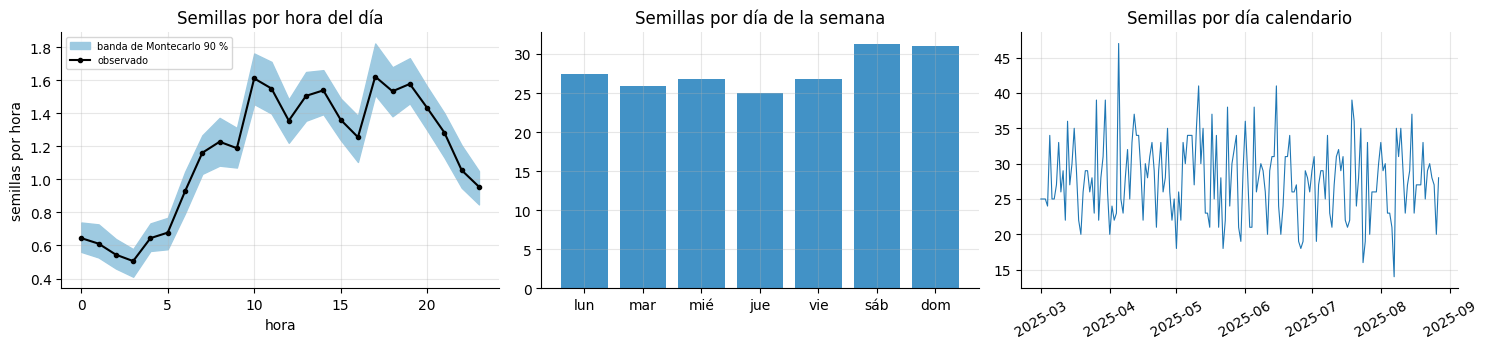

La muestra trae 4.998 semillas en 180,0 días: **27,8 piezas nuevas por día** en promedio. La tasa por hora va de 0,51 a 1,62 semillas por hora (mínimo a las 3 h, máximo a las 17 h), y sábado y domingo promedian 31,1 semillas por día contra 26,4 de lunes a viernes. El Poisson homogéneo da p de Montecarlo = 0,00; el no estacionario, p = 0,14. Una vez descontado el perfil día × hora, la dispersión de los conteos horarios es 0,96 (1 en un proceso de Poisson), así que las siembras no muestran ráfagas propias: las ráfagas del memo están en los reenvíos (sección 5.4).

In [15]:
lam_nspp = estimar_tasa(sem)
perfil_h = lam_nspp.groupby(lam_nspp.index.hour).mean()
perfil_d = lam_nspp.groupby(lam_nspp.index.dayofweek).mean() * 24
cnt_dia = pd.Series(1, index=sem).resample('D').sum()
sims_h = np.array([pd.Series(1, index=simular_nspp(lam_nspp)).resample('h').sum().reindex(horas, fill_value=0).groupby(horas.hour).mean().values for _ in range(100)])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].fill_between(range(24), np.quantile(sims_h, 0.05, 0), np.quantile(sims_h, 0.95, 0), color='#9ecae1', label='banda de Montecarlo 90 %')
ax[0].plot(range(24), perfil_h.values, 'k.-', label='observado')
ax[0].set_title('Semillas por hora del día'); ax[0].set_xlabel('hora'); ax[0].set_ylabel('semillas por hora'); ax[0].legend(fontsize=7)
ax[1].bar(['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom'], perfil_d.values, color='#4292c6'); ax[1].set_title('Semillas por día de la semana')
ax[2].plot(cnt_dia.index, cnt_dia.values, lw=0.8); ax[2].set_title('Semillas por día calendario'); ax[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

lexis_dia = cnt_dia.var() / cnt_dia.mean()
cnt_h = pd.Series(1, index=sem).resample('h').sum().reindex(horas, fill_value=0)
disp_h = ((cnt_h - lam_nspp) ** 2 / lam_nspp).mean()
fila_nh = tabla_siembra.iloc[1]; fila_h = tabla_siembra.iloc[0]
display(Markdown(
    f"La muestra trae {fmt(len(sem))} semillas en {fmt(n_dias, 1)} días: **{fmt(len(sem)/n_dias, 1)} piezas nuevas por día** en promedio. "
    f"La tasa por hora va de {fmt(perfil_h.min(), 2)} a {fmt(perfil_h.max(), 2)} semillas por hora (mínimo a las {int(perfil_h.idxmin())} h, máximo a las {int(perfil_h.idxmax())} h), "
    f"y sábado y domingo promedian {fmt(perfil_d.iloc[5:].mean(), 1)} semillas por día contra {fmt(perfil_d.iloc[:5].mean(), 1)} de lunes a viernes. "
    f"El Poisson homogéneo da p de Montecarlo = {fmt(fila_h['p Montecarlo'], 2)}; el no estacionario, p = {fmt(fila_nh['p Montecarlo'], 2)}. "
    f"Una vez descontado el perfil día × hora, la dispersión de los conteos horarios es {fmt(disp_h, 2)} (1 en un proceso de Poisson), "
    f"así que las siembras no muestran ráfagas propias: las ráfagas del memo están en los reenvíos (sección 5.4)."
))

### 5.2 Vida media de la pieza

Atributo de la pieza (constante en la cascada). La consigna dice que algunos temas mueren en minutos y otros persisten días (D5): positiva, asimétrica y con varios órdenes de magnitud, lo que sugiere lognormal.

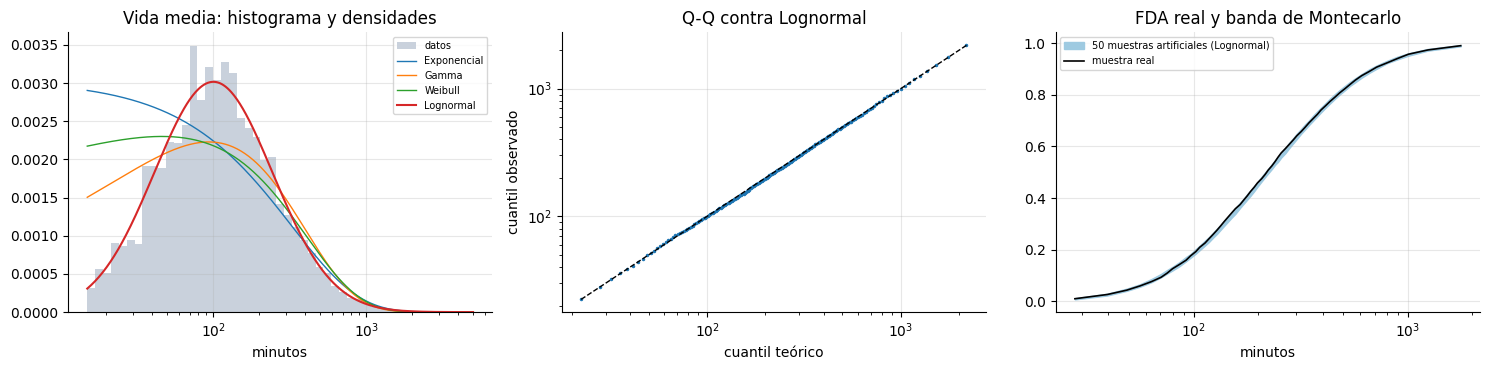

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Lognormal,"s=0.8891, loc=0, escala=220.8",66322.5,0.0101,0.0185,0.0228,0.245
1,Gamma,"a=1.397, loc=0, escala=235.5",66977.7,0.0717,0.0763,0.0227,0.000
2,Weibull,"c=1.118, loc=0, escala=345",67172.2,0.0648,0.0718,0.0237,0.000
3,Exponencial,"loc=0, escala=329",67284.3,0.1000,0.1072,0.0280,0.000


**Vida media de la pieza.** La candidata con menor AIC es **Lognormal** (s=0.8891, loc=0, escala=220.8), con D = 0,018 en la submuestra contra un crítico de Montecarlo de 0,023 (p de Montecarlo = 0,24). No se rechazan al 5 %: Lognormal.

,cuantil,real,artificial p5,artificial mediana,artificial p95
0,10 %,72.70,68.39,70.62,73.10
1,25 %,120.55,118.29,121.35,124.32
2,50 %,219.10,214.57,220.93,226.64
3,75 %,402.78,390.16,401.18,412.21
4,90 %,691.72,666.46,688.86,714.56
5,99 %,1766.85,1613.12,1733.28,1888.22


Mínimo observado: 15,0 min (7 piezas). Mediana 219,1 min; percentil 99 1.767 min.

In [16]:
x_vm = pieza.content_half_life_min.dropna().values
tabla_vm, aj_vm, mejor_vm = verificar_continua(x_vm, titulo='Vida media', unidad='minutos')
display(tabla_vm)
conclusion(tabla_vm, 'Vida media de la pieza')
display(cuantiles_artificiales(x_vm, *aj_vm[mejor_vm][:2]))
display(Markdown(f"Mínimo observado: {fmt(x_vm.min(), 1)} min ({fmt(int((x_vm == x_vm.min()).sum()))} piezas). "
                 f"Mediana {fmt(np.median(x_vm), 1)} min; percentil 99 {fmt(np.quantile(x_vm, .99), 0)} min."))

### 5.3 Hijos de cada reenvío

Es la variable central del proceso de ramificación (D2). Para una variable discreta, el cociente de Lexis orienta: igual a 1 sugiere Poisson y mayor que 1, binomial negativa, con la geométrica como caso particular de parámetro 1 (LAW p. 341 y p. 329). La consigna anticipa heterogeneidad (D3): una mezcla de Poisson con tasas distintas produce exactamente sobredispersión. Se ajusta por nivel de audiencia del que reenvía y por separado para semillas y reenvíos, sobre cascadas completas.

La verificación de Montecarlo usa el estadístico chi-cuadrado con clases 0, 1, ..., K y «K o más» (K tal que todas las clases esperen al menos 5 casos, BANKS-DES p. 360), reajustando la candidata en cada muestra artificial.

In [17]:
def nb_mle(x):
    m = x.mean()
    def nll(th):
        r = np.exp(th[0]); return -st.nbinom.logpmf(x, r, r / (r + m)).sum()
    v = x.var(); r0 = m * m / max(v - m, 1e-3)
    r = float(np.exp(so.minimize(nll, [np.log(max(r0, 0.05))], method='Nelder-Mead').x[0]))
    return r, r / (r + m)

def pmf_disc(nombre, x):
    m = x.mean()
    if nombre == 'Poisson':
        return (lambda k: st.poisson.pmf(k, m)), (lambda k: st.poisson.sf(k - 1, m)), f'media={m:.3f}', st.poisson.logpmf(x, m).sum(), 1, (lambda n: rng.poisson(m, n))
    if nombre == 'Geométrica':
        p = 1 / (1 + m)
        return (lambda k: st.geom.pmf(k + 1, p)), (lambda k: st.geom.sf(k, p)), f'p={p:.4f}', st.geom.logpmf(x + 1, p).sum(), 1, (lambda n: rng.geometric(p, n) - 1)
    r, p = nb_mle(x)
    return (lambda k: st.nbinom.pmf(k, r, p)), (lambda k: st.nbinom.sf(k - 1, r, p)), f'r={r:.3f}, p={p:.4f}', st.nbinom.logpmf(x, r, p).sum(), 2, (lambda n: rng.negative_binomial(r, p, n))

def chi2_disc(x, pmf, sf):
    n = len(x); K = 0
    while n * pmf(K + 1) >= 5 and n * sf(K + 2) >= 5 and K < 40: K += 1
    obs = np.array([(x == k).sum() for k in range(K + 1)] + [(x > K).sum()])
    esp = np.array([n * pmf(k) for k in range(K + 1)] + [n * sf(K + 1)])
    return ((obs - esp) ** 2 / esp).sum()

def verificar_discreta(x, B=B_MC, nsub=N_SUB):
    x = np.asarray(x, int); filas = []
    for nombre in ['Poisson', 'Geométrica', 'Binomial negativa']:
        pmf, sf, ptxt, ll, k, gen = pmf_disc(nombre, x)
        xs = rng.choice(x, min(nsub, len(x)), replace=False)
        pmf0, sf0, _, _, _, gen0 = pmf_disc(nombre, xs)
        c0 = chi2_disc(xs, pmf0, sf0)
        cs = []
        for b in range(B):
            y = gen0(len(xs)); pm, sfb, *_ = pmf_disc(nombre, y); cs.append(chi2_disc(y, pm, sfb))
        cs = np.array(cs)
        filas.append([nombre, ptxt, round(2 * k - 2 * ll, 1), round(c0, 1), round(float(np.quantile(cs, .95)), 1), float((cs >= c0).mean())])
    return pd.DataFrame(filas, columns=['candidata', 'parámetros', 'AIC', 'chi² submuestra', 'chi² crítico MC 95 %', 'p Montecarlo']).sort_values('AIC').reset_index(drop=True)

res_hijos = []
for semilla in [0, 1]:
    for nv in NIVELES:
        x = dfc.loc[(dfc.seed_flag == semilla) & (dfc.nivel == nv), 'hijos'].values
        t_ = verificar_discreta(x, B=B_MC if semilla == 0 else B_MC_AUX)
        r, p = nb_mle(x)
        for _, f in t_.iterrows():
            res_hijos.append(['semilla' if semilla else 'reenvío', nv, len(x), round(x.mean(), 3), round(x.var() / x.mean(), 2), *f.values])
res_hijos = pd.DataFrame(res_hijos, columns=['evento', 'nivel', 'n', 'media', 'Lexis', 'candidata', 'parámetros', 'AIC', 'chi² submuestra', 'chi² crítico MC 95 %', 'p Montecarlo'])
res_hijos

,evento,nivel,n,media,Lexis,candidata,parámetros,AIC,chi² submuestra,chi² crítico MC 95 %,p Montecarlo
0,reenvío,nano,44025,0.466,1.61,Binomial negativa,"r=0.816, p=0.6362",80697.2,1.3,6.6,0.695
1,reenvío,nano,44025,0.466,1.61,Geométrica,p=0.6819,80757.3,1.8,7.5,0.660
2,reenvío,nano,44025,0.466,1.61,Poisson,media=0.466,84819.8,99.8,5.8,0.000
3,reenvío,micro,3605,0.774,2.11,Binomial negativa,"r=0.727, p=0.4844",8737.4,3.5,12.1,0.620
4,reenvío,micro,3605,0.774,2.11,Geométrica,p=0.5638,8761.5,19.5,11.4,0.000
5,reenvío,micro,3605,0.774,2.11,Poisson,media=0.774,9670.0,453.8,7.8,0.000
6,reenvío,macro,3349,2.366,3.84,Binomial negativa,"r=0.903, p=0.2763",13713.3,10.8,19.5,0.540
7,reenvío,macro,3349,2.366,3.84,Geométrica,p=0.2971,13718.3,15.5,21.6,0.170
8,reenvío,macro,3349,2.366,3.84,Poisson,media=2.366,17376.3,1764.0,12.5,0.000
9,reenvío,mega,3014,3.668,5.16,Binomial negativa,"r=0.935, p=0.2031",14617.7,19.5,25.9,0.195


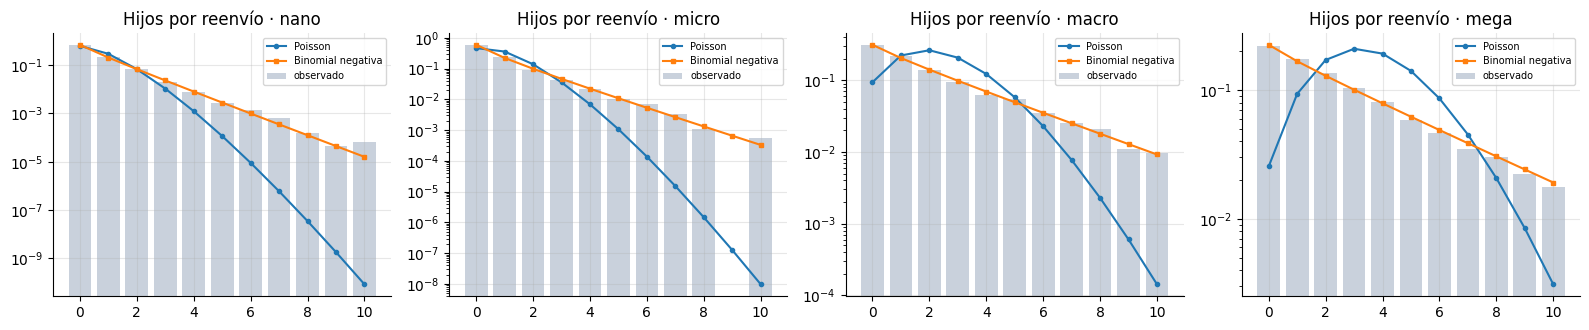

El cociente de Lexis va de 1,61 a 6,93: siempre mayor que 1, así que la Poisson queda descartada (su p de Montecarlo máximo es 0,00). El parámetro r de la binomial negativa queda entre 0,73 y 1,30: muy cerca de 1, que es la geométrica. Por eso binomial negativa y geométrica empatan en AIC en casi todos los grupos. La media de hijos por reenvío crece con el nivel de audiencia, de 0,47 (nano) a 3,67 (mega), y las semillas tienen más hijos que los reenvíos del mismo nivel.

In [18]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a, nv in zip(ax, NIVELES):
    x = dfc.loc[(dfc.seed_flag == 0) & (dfc.nivel == nv), 'hijos'].values
    ks = np.arange(0, 11); r, p = nb_mle(x); m = x.mean()
    a.bar(ks, [(x == k).mean() for k in ks], color='#c9d1dc', label='observado')
    a.plot(ks, st.poisson.pmf(ks, m), 'o-', ms=3, label='Poisson')
    a.plot(ks, st.nbinom.pmf(ks, r, p), 's-', ms=3, label='Binomial negativa')
    a.set_title(f'Hijos por reenvío · {nv}'); a.set_yscale('log'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

ganan = res_hijos.groupby(['evento', 'nivel'], observed=True).apply(lambda g: g.sort_values('AIC').candidata.iloc[0])
nb_r = res_hijos[res_hijos.candidata == 'Binomial negativa']
r_vals = nb_r.parámetros.str.extract(r'r=([0-9.]+)')[0].astype(float)
poi = res_hijos[res_hijos.candidata == 'Poisson']
display(Markdown(
    f"El cociente de Lexis va de {fmt(res_hijos.Lexis.min(), 2)} a {fmt(res_hijos.Lexis.max(), 2)}: siempre mayor que 1, así que la Poisson queda descartada "
    f"(su p de Montecarlo máximo es {fmt(poi['p Montecarlo'].max(), 2)}). "
    f"El parámetro r de la binomial negativa queda entre {fmt(r_vals.min(), 2)} y {fmt(r_vals.max(), 2)}: muy cerca de 1, que es la geométrica. "
    f"Por eso binomial negativa y geométrica empatan en AIC en casi todos los grupos. "
    f"La media de hijos por reenvío crece con el nivel de audiencia, de {fmt(dfc[(dfc.seed_flag==0)&(dfc.nivel=='nano')].hijos.mean(), 2)} (nano) a {fmt(dfc[(dfc.seed_flag==0)&(dfc.nivel=='mega')].hijos.mean(), 2)} (mega), "
    f"y las semillas tienen más hijos que los reenvíos del mismo nivel."
))

### 5.4 Retardo entre un reenvío y sus hijos

Es el tiempo entre generaciones. Si la consigna describe «ráfagas» (D8), parte de los reenvíos tiene que llegar muy rápido después del padre. Se prueban primero las cuatro familias simples. Para las mezclas se usan 60 réplicas de Montecarlo en lugar de 200, porque cada reajuste es una optimización de cinco o seis parámetros. Para poder probar también mezclas con la misma maquinaria, se definen dos distribuciones propias con la misma interfaz que las de `scipy`: una normal truncada en [0, 1] (que se usa en 5.7) y una mezcla de dos componentes, una rápida desde 0 y una diferida desde un desplazamiento S.

In [19]:
class NormalTruncada01:
    # Normal truncada al intervalo [0, 1]; parámetros (mu, sigma)
    shapes = None; numargs = 0; k_libres = 2
    def _ab(self, mu, s): return (0 - mu) / s, (1 - mu) / s
    def pdf(self, x, mu, s): a, b = self._ab(mu, s); return st.truncnorm.pdf(x, a, b, mu, s)
    def logpdf(self, x, mu, s): a, b = self._ab(mu, s); return st.truncnorm.logpdf(x, a, b, mu, s)
    def cdf(self, x, mu, s): a, b = self._ab(mu, s); return st.truncnorm.cdf(x, a, b, mu, s)
    def ppf(self, q, mu, s): a, b = self._ab(mu, s); return st.truncnorm.ppf(q, a, b, mu, s)
    def rvs(self, mu, s, size=1, random_state=None): a, b = self._ab(mu, s); return st.truncnorm.rvs(a, b, mu, s, size=size, random_state=random_state)
    def fit(self, x, **kw):
        f = lambda th: -self.logpdf(x, th[0], np.exp(th[1])).sum()
        th = so.minimize(f, [np.mean(x), np.log(np.std(x))], method='Nelder-Mead').x
        return (th[0], float(np.exp(th[1])))
    def describe(self, p): return f'mu={p[0]:.4g}, sigma={p[1]:.4g}'

class Mezcla:
    # w·A(x) + (1−w)·LogNormal(x − S) para x > S. A es una familia de scipy con loc = 0.
    shapes = None; numargs = 0
    def __init__(self, A, S, nombre):
        self.A, self.S, self.nombre = A, S, nombre
        self.kA = A.numargs + 1; self.k_libres = 1 + self.kA + 2
    def _split(self, th):
        w = th[0]; pa = th[1:1 + self.kA]; mu, sg = th[1 + self.kA], th[2 + self.kA]
        return w, pa, mu, sg
    def pdf(self, x, *th):
        w, pa, mu, sg = self._split(th); x = np.asarray(x, float)
        fa = self.A.pdf(x, *pa[:-1], loc=0, scale=pa[-1])
        fb = np.where(x > self.S, st.lognorm.pdf(np.maximum(x - self.S, 1e-12), sg, scale=np.exp(mu)), 0)
        return w * fa + (1 - w) * fb
    def logpdf(self, x, *th): return np.log(self.pdf(x, *th) + 1e-300)
    def cdf(self, x, *th):
        w, pa, mu, sg = self._split(th); x = np.asarray(x, float)
        return w * self.A.cdf(x, *pa[:-1], loc=0, scale=pa[-1]) + (1 - w) * st.lognorm.cdf(np.maximum(x - self.S, 0), sg, scale=np.exp(mu))
    def rvs(self, *th, size=1, random_state=None):
        w, pa, mu, sg = self._split(th); r = random_state or rng
        a = r.random(size) < w
        xa = self.A.rvs(*pa[:-1], loc=0, scale=pa[-1], size=size, random_state=r)
        xb = self.S + r.lognormal(mu, sg, size)
        return np.where(a, xa, xb)
    def ppf(self, q, *th):
        g = np.concatenate([np.logspace(-4, 0, 200), np.logspace(0, 5, 800)])
        c = self.cdf(g, *th); return np.interp(q, c, g)
    def fit(self, x, **kw):
        x = np.maximum(np.asarray(x, float), 1e-3)
        def unpack(z):
            w = 1 / (1 + np.exp(-z[0])); pa = list(np.exp(z[1:1 + self.kA])); return [w, *pa, z[1 + self.kA], np.exp(z[2 + self.kA])]
        nll = lambda z: -self.logpdf(x, *unpack(z)).sum()
        mejor = None
        for z0 in ([0.8] + [0.0] * (self.kA - 1) + [np.log(20), 3.3, -0.4], [0.3] + [-0.5] * (self.kA - 1) + [np.log(10), 3.0, 0.0]):
            r = so.minimize(nll, z0, method='Nelder-Mead', options={'maxiter': 4000, 'maxfev': 4000, 'xatol': 1e-4, 'fatol': 1e-3})
            if mejor is None or r.fun < mejor.fun: mejor = r
        return tuple(unpack(mejor.x))
    def describe(self, p):
        w, pa, mu, sg = self._split(p)
        return f'w={w:.3f}; rápida {self.nombre}({", ".join(f"{v:.3g}" for v in pa)}); diferida {self.S:g} + LN(mu={mu:.3f}, sigma={sg:.3f})'

# parches para que las herramientas comunes acepten las distribuciones propias
def n_libres(d, kw):
    return getattr(d, 'k_libres', None) or (d.numargs + 2 - sum(k in kw for k in ('floc', 'fscale')))
def describir_params(d, p):
    if hasattr(d, 'describe'): return d.describe(p)
    nombres = (d.shapes.split(', ') if d.shapes else []) + ['loc', 'escala']
    return ', '.join(f'{n}={v:.4g}' for n, v in zip(nombres, p))

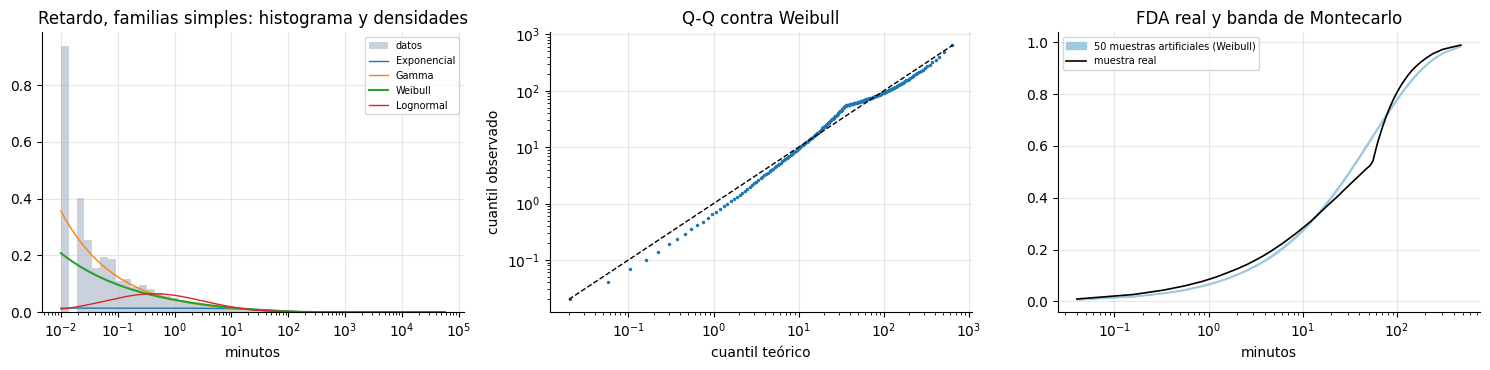

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Weibull,"c=0.6733, loc=0, escala=53.3",547461.1,0.1060,0.1069,0.0240,0.0
1,Gamma,"a=0.5433, loc=0, escala=129.6",548392.4,0.0794,0.0899,0.0245,0.0
2,Lognormal,"s=1.983, loc=0, escala=22.21",560219.7,0.1424,0.1497,0.0240,0.0
3,Exponencial,"loc=0, escala=70.44",565682.0,0.1515,0.1403,0.0287,0.0


**Retardo padre-hijo con familias simples.** La candidata con menor AIC es **Weibull** (c=0.6733, loc=0, escala=53.3), con D = 0,107 en la submuestra contra un crítico de Montecarlo de 0,024 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

In [20]:
x_ret = dfc.loc[dfc.seed_flag == 0, 'inter_event_time_min'].values
x_ret = x_ret[x_ret > 0]
tabla_ret1, aj_ret1, _ = verificar_continua(x_ret, titulo='Retardo, familias simples', unidad='minutos')
display(tabla_ret1)
conclusion(tabla_ret1, 'Retardo padre-hijo con familias simples')

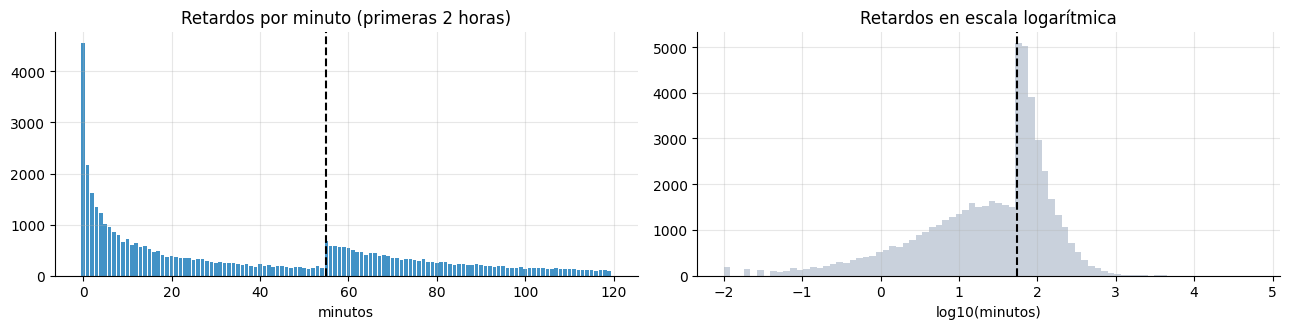

La cantidad de retardos por minuto se multiplica por 4,4 al llegar al minuto 55: hay dos poblaciones. La rápida arranca en 0 con una densidad muy concentrada cerca del origen; la diferida arranca recién en 55 minutos. Es el caso de mezcla de poblaciones heterogéneas que LAW (p. 303) señala como aquel en que ninguna familia teórica única ajusta.

In [21]:
# El histograma minuto a minuto muestra un salto: ahí empieza la componente diferida
cnt_min = np.bincount(np.floor(x_ret[x_ret < 120]).astype(int), minlength=120)
razon = cnt_min[5:] / np.array([cnt_min[i - 5:i].mean() for i in range(5, 120)])
S_RET = float(5 + np.argmax(razon))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].bar(range(120), cnt_min, color='#4292c6'); ax[0].axvline(S_RET, color='k', ls='--'); ax[0].set_title('Retardos por minuto (primeras 2 horas)'); ax[0].set_xlabel('minutos')
ax[1].hist(np.log10(x_ret), bins=80, color='#c9d1dc'); ax[1].axvline(np.log10(S_RET), color='k', ls='--'); ax[1].set_title('Retardos en escala logarítmica'); ax[1].set_xlabel('log10(minutos)')
plt.tight_layout(); plt.show()
display(Markdown(f"La cantidad de retardos por minuto se multiplica por {fmt(razon.max(), 1)} al llegar al minuto {int(S_RET)}: hay dos poblaciones. "
                 f"La rápida arranca en 0 con una densidad muy concentrada cerca del origen; la diferida arranca recién en {int(S_RET)} minutos. "
                 f"Es el caso de mezcla de poblaciones heterogéneas que LAW (p. 303) señala como aquel en que ninguna familia teórica única ajusta."))

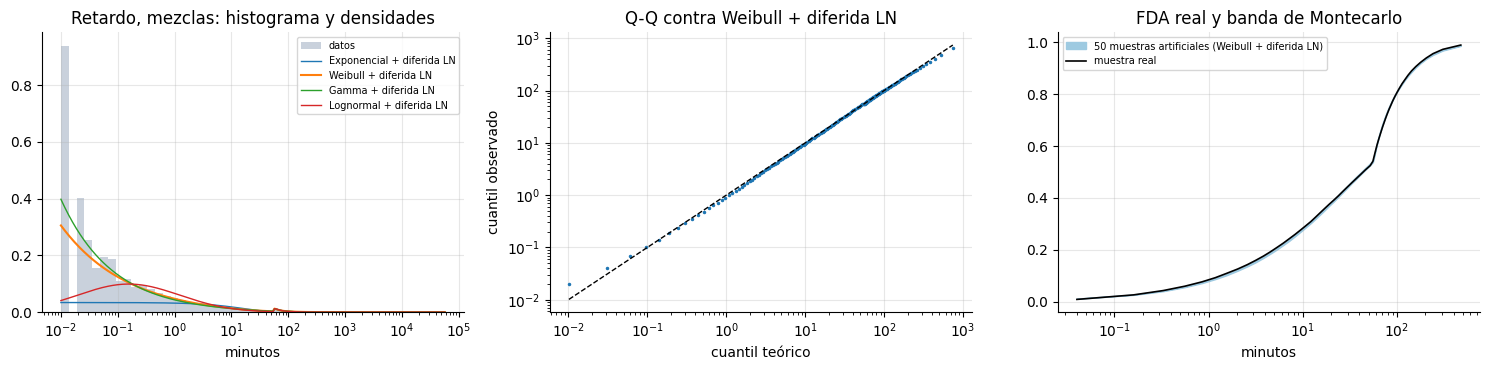

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Weibull + diferida LN,"w=0.701; rápida Weibull(0.619, 29.7); diferida...",538379.0,0.0110,0.0223,0.0169,0.0
1,Gamma + diferida LN,"w=0.703; rápida Gamma(0.521, 74.5); diferida 5...",538804.0,0.0187,0.0283,0.0209,0.0
2,Lognormal + diferida LN,"w=0.671; rápida Lognormal(2.06, 11); diferida ...",541917.9,0.0406,0.0334,0.0195,0.0
3,Exponencial + diferida LN,w=0.555; rápida Exponencial(16.4); diferida 55...,544891.2,0.0627,0.0719,0.0183,0.0


**Retardo padre-hijo con mezclas.** La candidata con menor AIC es **Weibull + diferida LN** (w=0.701; rápida Weibull(0.619, 29.7); diferida 55 + LN(mu=3.236, sigma=1.522)), con D = 0,022 en la submuestra contra un crítico de Montecarlo de 0,017 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

,cuantil,real,artificial p5,artificial mediana,artificial p95
0,10 %,1.34,1.39,1.45,1.49
1,25 %,7.66,7.71,7.91,8.12
2,50 %,43.74,41.65,42.63,43.62
3,75 %,84.31,81.77,82.52,83.17
4,90 %,151.68,151.52,153.66,155.64
5,99 %,476.87,512.13,529.99,545.28


Con la mezcla elegida, el 70 % de los reenvíos ocurre en la componente rápida y el 30 % en la diferida. La media del retardo es 70,4 minutos y la mediana 43,7.

In [22]:
mezclas = {f'{a} + diferida LN': Mezcla(d, S_RET, a) for a, d in [('Exponencial', st.expon), ('Weibull', st.weibull_min), ('Gamma', st.gamma), ('Lognormal', st.lognorm)]}
tabla_ret2, aj_ret2, mejor_ret = verificar_continua(x_ret, familias=mezclas, B=60, titulo='Retardo, mezclas', unidad='minutos')
display(tabla_ret2)
conclusion(tabla_ret2, 'Retardo padre-hijo con mezclas')
d_ret, p_ret, _ = aj_ret2[mejor_ret]
display(cuantiles_artificiales(x_ret, d_ret, p_ret))
w_ret = p_ret[0]
display(Markdown(f"Con la mezcla elegida, el {pct(w_ret, 0)} de los reenvíos ocurre en la componente rápida y el {pct(1 - w_ret, 0)} en la diferida. "
                 f"La media del retardo es {fmt(x_ret.mean(), 1)} minutos y la mediana {fmt(np.median(x_ret), 1)}."))

In [23]:
# ¿Algún atributo explica a qué componente pertenece un reenvío?
dd = dfc[dfc.seed_flag == 0].copy(); dd['diferido'] = (dd.inter_event_time_min >= S_RET).astype(int)
por_attr = pd.concat([dd.groupby(c).diferido.mean().rename('proporción diferida').to_frame().assign(atributo=c).reset_index().rename(columns={c: 'valor'})
                      for c in ['platform_surface_code', 'content_type_code', 'nivel', 'c2', 'nociva', 'account_type_code']])
display(por_attr.pivot_table(index='atributo', values='proporción diferida', aggfunc=['min', 'max']).round(3))

,min,max
,proporción diferida,proporción diferida
atributo,,
account_type_code,0.458,0.471
c2,0.462,0.465
content_type_code,0.461,0.472
nivel,0.459,0.465
nociva,0.459,0.468
platform_surface_code,0.461,0.467


### 5.5 Seguidores por cuenta

La consigna anticipa cola pesada (D7): mediana de cientos y cuentas con millones. Como los seguidores de una misma cuenta casi no varían entre eventos, se usa un valor por cuenta (la mediana) y se separan los roles, porque cada uno tiene un piso distinto: los creadores arrancan cerca de 50.000 seguidores, los difusores masivos cerca de 200.000, y las cuentas estándar, durmientes y reposteadoras en 300. Para esta segunda población se prueban familias desplazadas a 300 y la Pareto, que es la forma clásica de una cola de potencia.

,count,mean,std,min,5%,50%,95%,max
rol,,,,,,,,
AGGREGATOR,902.0,1649.0,5673.0,300.0,308.0,412.0,4560.0,47861.0
BROADCASTER,114.0,549998.0,479092.0,205753.0,211011.0,405467.0,1303176.0,3503446.0
CREATOR,233.0,121709.0,130736.0,50182.0,54149.0,100286.0,197336.0,1915448.0
LURKER,779.0,1861.0,6426.0,300.0,310.0,409.0,4527.0,48158.0
STANDARD,1972.0,1692.0,6194.0,300.0,307.0,415.0,2349.0,49777.0


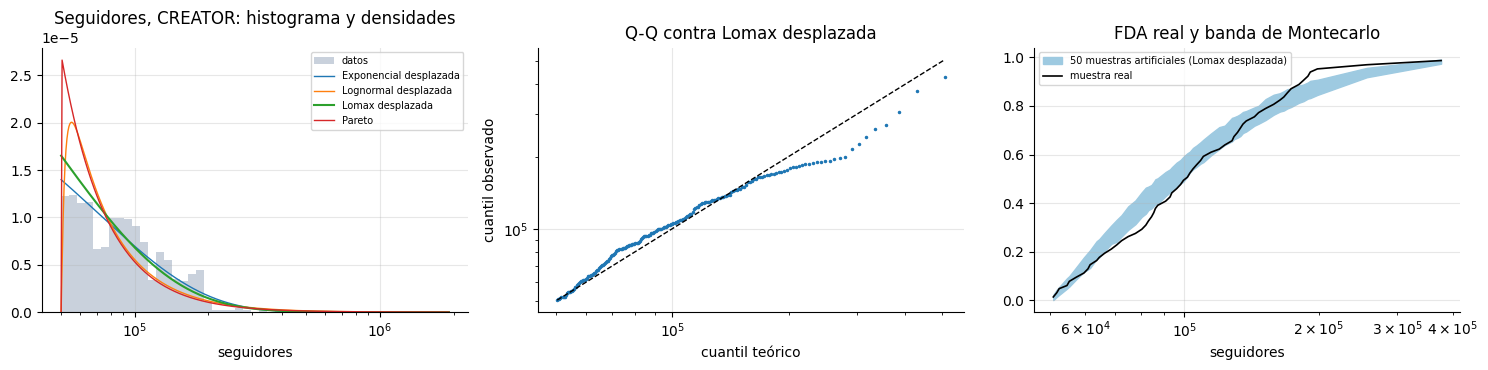

**CREATOR** · 233 cuentas · piso 50.182 seguidores

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Lomax desplazada,"c=7.866, loc=5.018e+04, escala=4.763e+05",5660.5,0.0960,0.0960,0.0610,0.000
1,Exponencial desplazada,"loc=5.018e+04, escala=7.153e+04",5676.9,0.0824,0.0824,0.0665,0.005
2,Pareto,"b=1.364, loc=0, escala=5.018e+04",5708.7,0.1856,0.1856,0.0663,0.000
3,Lognormal desplazada,"s=1.415, loc=5.018e+04, escala=3.826e+04",5744.2,0.1455,0.1455,0.0550,0.000


**Seguidores de CREATOR.** La candidata con menor AIC es **Lomax desplazada** (c=7.866, loc=5.018e+04, escala=4.763e+05), con D = 0,096 en la submuestra contra un crítico de Montecarlo de 0,061 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

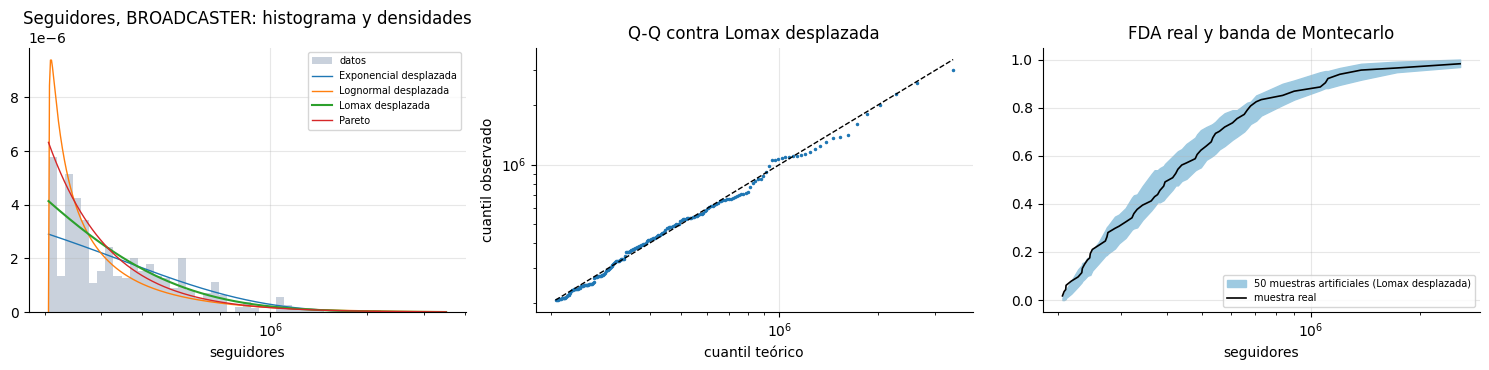

**BROADCASTER** · 114 cuentas · piso 205.753 seguidores

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Lomax desplazada,"c=3.274, loc=2.058e+05, escala=7.915e+05",3127.9,0.0642,0.0642,0.0821,0.240
1,Pareto,"b=1.301, loc=0, escala=2.058e+05",3134.7,0.1258,0.1258,0.1021,0.005
2,Exponencial desplazada,"loc=2.058e+05, escala=3.442e+05",3136.8,0.1069,0.1069,0.1070,0.055
3,Lognormal desplazada,"s=1.905, loc=2.058e+05, escala=1.362e+05",3169.8,0.1340,0.1340,0.0816,0.000


**Seguidores de BROADCASTER.** La candidata con menor AIC es **Lomax desplazada** (c=3.274, loc=2.058e+05, escala=7.915e+05), con D = 0,064 en la submuestra contra un crítico de Montecarlo de 0,082 (p de Montecarlo = 0,24). No se rechazan al 5 %: Lomax desplazada, Exponencial desplazada.

In [24]:
cuentas = df.dropna(subset=['actor_follower_count']).groupby('actor_id').agg(seg=('actor_follower_count', 'median'), rol=('account_type_code', 'first'),
                                                                             verif=('verified_flag', 'first'), edad=('account_age_days', 'first'), siguiendo=('actor_following_count', 'median'))
chicas = cuentas[~cuentas.rol.isin(['BROADCASTER', 'CREATOR'])].seg.values
display(cuentas.groupby('rol').seg.describe(percentiles=[.05, .5, .95]).round(0))

# difusores y creadores son dos poblaciones con pisos distintos: se ajustan por separado, desplazadas a su mínimo
seg_roles = {}
for rol in ['CREATOR', 'BROADCASTER']:
    x = cuentas[cuentas.rol == rol].seg.values; piso = float(x.min()) - 1
    fam = {'Exponencial desplazada': st.expon, 'Lognormal desplazada': st.lognorm, 'Lomax desplazada': st.lomax, 'Pareto': st.pareto}
    kw = {k: {'floc': piso} for k in fam}; kw['Pareto'] = {'floc': 0, 'fscale': piso + 1}
    t_, a_, m_ = verificar_continua(x, familias=fam, kw_extra=kw, titulo=f'Seguidores, {rol}', unidad='seguidores')
    display(Markdown(f'**{rol}** · {len(x)} cuentas · piso {fmt(int(piso + 1))} seguidores')); display(t_); conclusion(t_, f'Seguidores de {rol}')
    seg_roles[rol] = (t_, a_, m_)
tabla_seg_g, aj_seg_g, mejor_seg_g = seg_roles['BROADCASTER']

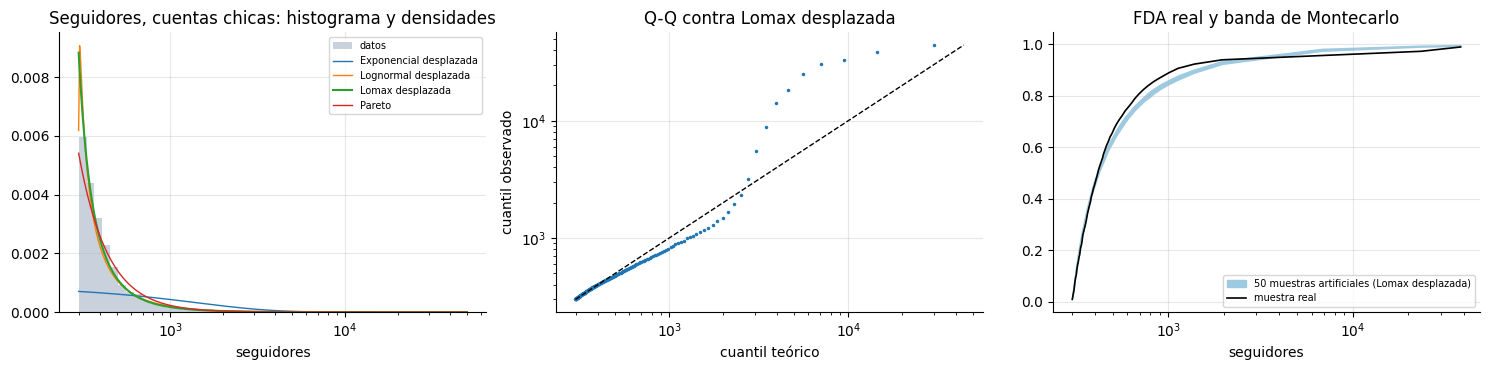

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Lomax desplazada,"c=0.9352, loc=299, escala=103.9",49540.1,0.0415,0.0412,0.0203,0.0
1,Lognormal desplazada,"s=1.8, loc=299, escala=123.5",49851.6,0.0685,0.0748,0.0238,0.0
2,Pareto,"b=1.622, loc=0, escala=300",49947.2,0.1048,0.1063,0.0277,0.0
3,Exponencial desplazada,"loc=299, escala=1418",60328.4,0.5675,0.5760,0.0271,0.0


**Seguidores de cuentas estándar, durmientes y reposteadoras.** La candidata con menor AIC es **Lomax desplazada** (c=0.9352, loc=299, escala=103.9), con D = 0,041 en la submuestra contra un crítico de Montecarlo de 0,020 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

,cuantil,real,artificial p5,artificial mediana,artificial p95
0,10 %,315.0,310.41,311.50,312.59
1,25 %,341.0,334.32,336.60,339.07
2,50 %,413.0,407.52,413.48,419.48
3,75 %,597.0,629.90,653.52,676.60
4,90 %,1082.8,1316.58,1419.73,1535.22
5,99 %,38494.8,10858.67,14343.79,18929.78


In [25]:
fam_chicas = {'Exponencial desplazada': st.expon, 'Lognormal desplazada': st.lognorm, 'Lomax desplazada': st.lomax, 'Pareto': st.pareto}
kw_chicas = {'Exponencial desplazada': {'floc': 299}, 'Lognormal desplazada': {'floc': 299}, 'Lomax desplazada': {'floc': 299}, 'Pareto': {'floc': 0, 'fscale': 300}}
tabla_seg_c, aj_seg_c, mejor_seg_c = verificar_continua(chicas, familias=fam_chicas, kw_extra=kw_chicas, titulo='Seguidores, cuentas chicas', unidad='seguidores')
display(tabla_seg_c); conclusion(tabla_seg_c, 'Seguidores de cuentas estándar, durmientes y reposteadoras')
d_, p_, _ = aj_seg_c[mejor_seg_c]
display(cuantiles_artificiales(chicas, d_, p_))

### 5.6 Impresiones de cada reenvío

Las impresiones crecen casi en proporción a los seguidores (sección 6.2), así que conviene modelarlas como seguidores × fracción alcanzada. La fracción vive entre 0 y 1, lo que sugiere una Beta; se compara con familias positivas genéricas.

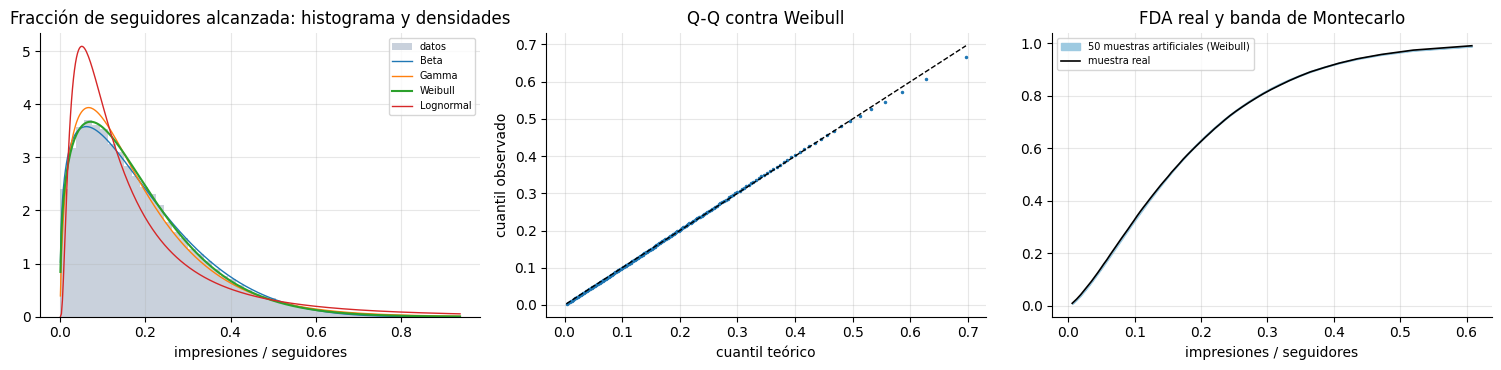

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Weibull,"c=1.336, loc=0, escala=0.2",-98364.6,0.0063,0.0137,0.0238,0.710
1,Beta,"a=1.312, b=5.796, loc=0, escala=1",-98326.3,0.0093,0.0209,0.0239,0.105
2,Gamma,"a=1.568, loc=0, escala=0.1173",-97666.1,0.0202,0.0256,0.0241,0.025
3,Lognormal,"s=0.9689, loc=0, escala=0.1294",-85967.4,0.0721,0.0791,0.0238,0.000


**Fracción de seguidores alcanzada.** La candidata con menor AIC es **Weibull** (c=1.336, loc=0, escala=0.2), con D = 0,014 en la submuestra contra un crítico de Montecarlo de 0,024 (p de Montecarlo = 0,71). No se rechazan al 5 %: Weibull, Beta.

Se excluyen 1 eventos con impresiones mayores o iguales a los seguidores. Mediana de la fracción por nivel: nano 0,152, micro 0,155, macro 0,154, mega 0,156.

In [26]:
frac = (df.impressions / df.actor_follower_count).dropna()
fuera = (frac >= 1).sum()
frac = frac[(frac > 0) & (frac < 1)].values
fam_frac = {'Beta': st.beta, 'Gamma': st.gamma, 'Weibull': st.weibull_min, 'Lognormal': st.lognorm}
tabla_frac, aj_frac, mejor_frac = verificar_continua(frac, familias=fam_frac, kw_extra={'Beta': {'floc': 0, 'fscale': 1}}, titulo='Fracción de seguidores alcanzada', log_x=False, unidad='impresiones / seguidores')
display(tabla_frac); conclusion(tabla_frac, 'Fracción de seguidores alcanzada')
display(Markdown(f"Se excluyen {fmt(int(fuera))} eventos con impresiones mayores o iguales a los seguidores. "
                 f"Mediana de la fracción por nivel: " + ', '.join(f"{nv} {fmt(v, 3)}" for nv, v in df.assign(f=df.impressions / df.actor_follower_count).groupby('nivel', observed=True).f.median().items()) + "."))

### 5.7 Puntaje de nocividad

El puntaje de Centinela vive en [0, 1] y cambia evento a evento dentro de una misma cascada (sección 2.2); la celda compara cuánto varía dentro y entre cascadas. Se ajusta por separado para piezas nocivas y legítimas, con dos candidatas acotadas al intervalo: Beta y normal truncada.

,mean,std,prop. en 0,prop. en 1
topic_code,,,,
DISARM-T0003,0.413,0.202,0.002,0.000
DISARM-T0023,0.419,0.175,0.000,0.001
DISARM-T0039,0.461,0.185,0.000,0.002
DISARM-T0049,0.460,0.195,0.001,0.000
DISARM-T0049.003,0.492,0.223,0.000,0.005
ORG-CELEB,0.226,0.148,0.022,0.000
ORG-FIN,0.243,0.140,0.012,0.000
ORG-HLTH,0.256,0.137,0.012,0.000
ORG-LOCAL,0.275,0.176,0.025,0.000


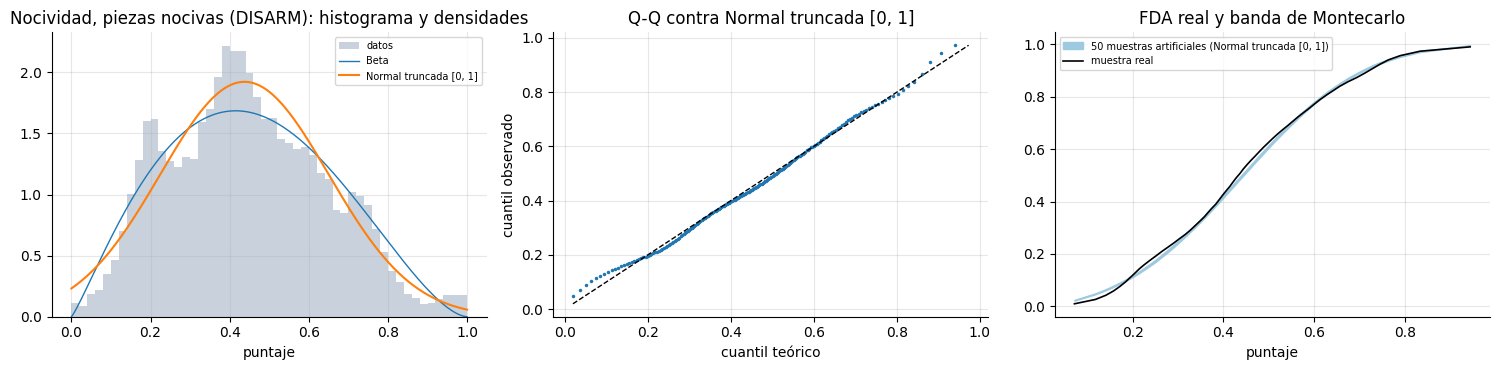

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,"Normal truncada [0, 1]","mu=0.4374, sigma=0.2125",-11556.4,0.0236,0.0428,0.0228,0.0
1,Beta,"a=2.176, b=2.658, loc=0, escala=1",-10289.1,0.0347,0.0395,0.0237,0.0


**Puntaje de nocividad en piezas nocivas (DISARM).** La candidata con menor AIC es **Normal truncada [0, 1]** (mu=0.4374, sigma=0.2125), con D = 0,043 en la submuestra contra un crítico de Montecarlo de 0,023 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

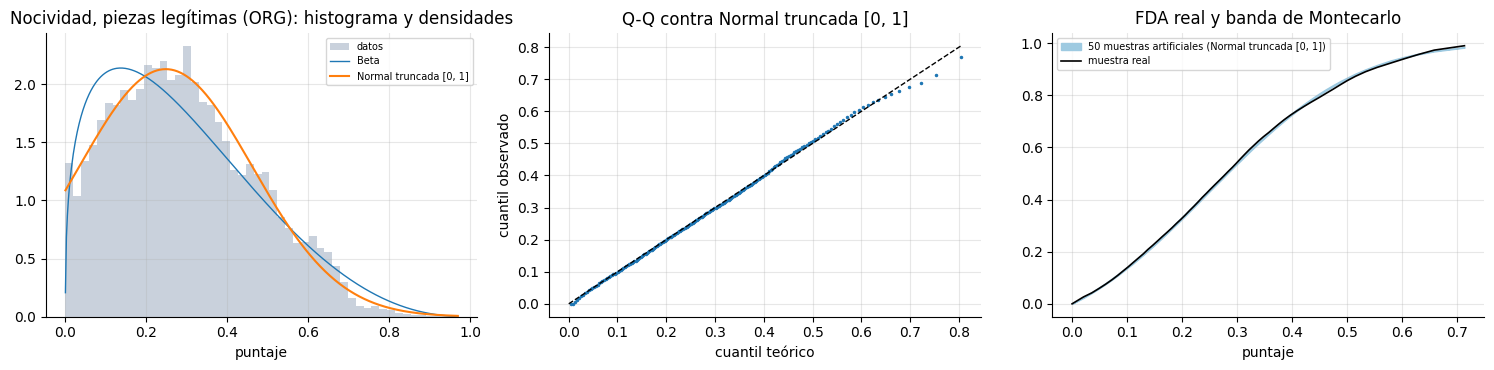

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,"Normal truncada [0, 1]","mu=0.2478, sigma=0.2137",-31241.6,0.0131,0.0163,0.0208,0.395
1,Beta,"a=1.371, b=3.348, loc=0, escala=1",-28565.6,0.0547,0.0656,0.0238,0.000


**Puntaje de nocividad en piezas legítimas (ORG).** La candidata con menor AIC es **Normal truncada [0, 1]** (mu=0.2478, sigma=0.2137), con D = 0,016 en la submuestra contra un crítico de Montecarlo de 0,021 (p de Montecarlo = 0,40). No se rechazan al 5 %: Normal truncada [0, 1].

Varianza del puntaje entre cascadas: 0,0391; dentro de una misma cascada: 0,0009. El puntaje cambia evento a evento, pero muy poco: es sobre todo un atributo de la pieza, con un ruido chico por evento.

In [27]:
display(df.groupby('topic_code').toxicity_index.agg(['mean', 'std', lambda v: (v == 0).mean(), lambda v: (v == 1).mean()]).rename(columns={'<lambda_0>': 'prop. en 0', '<lambda_1>': 'prop. en 1'}).round(3))
var_entre = df.groupby('cascade_id').toxicity_index.mean().var(); var_dentro = df.groupby('cascade_id').toxicity_index.var().mean()
tox_tablas = {}
for grupo, etiqueta in [(1, 'piezas nocivas (DISARM)'), (0, 'piezas legítimas (ORG)')]:
    x = df.loc[df.nociva == grupo, 'toxicity_index'].clip(1e-4, 1 - 1e-4).values
    t_, a_, m_ = verificar_continua(x, familias={'Beta': st.beta, 'Normal truncada [0, 1]': NormalTruncada01()}, kw_extra={'Beta': {'floc': 0, 'fscale': 1}}, titulo=f'Nocividad, {etiqueta}', log_x=False, unidad='puntaje')
    display(t_); conclusion(t_, f'Puntaje de nocividad en {etiqueta}'); tox_tablas[grupo] = (t_, a_, m_)
display(Markdown(f"Varianza del puntaje entre cascadas: {fmt(var_entre, 4)}; dentro de una misma cascada: {fmt(var_dentro, 4)}. "
                 + ("El puntaje cambia evento a evento, pero muy poco: es sobre todo un atributo de la pieza, con un ruido chico por evento." if var_entre > 5 * var_dentro
                    else "El puntaje es sobre todo un atributo del evento, no de la pieza.")))

### 5.8 Marcado por Centinela

Cada evento se marca o no: es una Bernoulli. La consigna sugiere que la probabilidad depende del tema y del puntaje (D10). Se estima una regresión logística y se verifica por Montecarlo: se generan marcados artificiales con las probabilidades ajustadas y se compara la tasa observada por decil de puntaje con la banda de las réplicas.

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-2.2092,0.0222,-99.4052,0.0000,-2.2528,-2.1657
C(nivel)[T.micro],0.0204,0.0381,0.5348,0.5928,-0.0543,0.0950
C(nivel)[T.macro],-0.0187,0.0460,-0.4072,0.6838,-0.1090,0.0715
C(nivel)[T.mega],-0.0957,0.0541,-1.7694,0.0768,-0.2017,0.0103
toxicity_index,1.9098,0.0504,37.8820,0.0000,1.8109,2.0086
nociva,0.6645,0.0201,33.0411,0.0000,0.6251,0.7039
verified_flag,0.0035,0.0436,0.0804,0.9359,-0.0819,0.0889


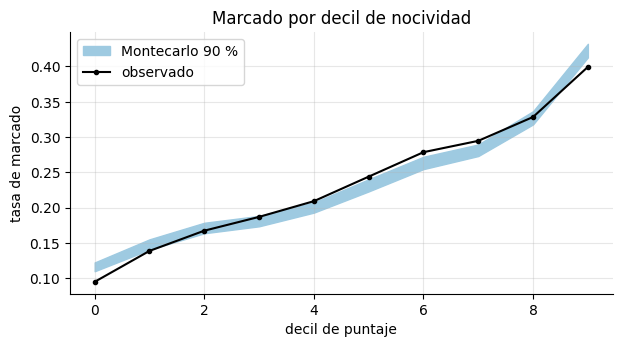

Tasa de marcado por evento: 33,6 % en piezas nocivas y 16,7 % en legítimas. El coeficiente de cuenta verificada es 0,004 (p = 0,936): en el marcado no aparece la indulgencia con cuentas verificadas que menciona el memo. La tasa observada queda fuera de la banda de Montecarlo en 7 de los 10 deciles.

In [28]:
dfl = df.dropna(subset=['nivel']).copy()
logit = smf.glm('moderation_flag ~ toxicity_index + nociva + verified_flag + C(nivel)', data=dfl, family=sm.families.Binomial()).fit()
display(logit.summary2().tables[1].round(4))
p_hat = logit.predict(dfl)
dec = pd.qcut(dfl.toxicity_index.rank(method='first'), 10, labels=False)
obs_dec = dfl.moderation_flag.groupby(dec).mean()
sims = np.array([pd.Series(rng.random(len(dfl)) < p_hat.values).groupby(dec.values).mean().values for _ in range(B_MC)])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.fill_between(range(10), np.quantile(sims, .05, 0), np.quantile(sims, .95, 0), color='#9ecae1', label='Montecarlo 90 %')
ax.plot(range(10), obs_dec.values, 'k.-', label='observado'); ax.set_xlabel('decil de puntaje'); ax.set_ylabel('tasa de marcado'); ax.legend(); ax.set_title('Marcado por decil de nocividad')
plt.show()
fuera_banda = int(((obs_dec.values < np.quantile(sims, .05, 0)) | (obs_dec.values > np.quantile(sims, .95, 0))).sum())
tasa = df.groupby('nociva').moderation_flag.mean()
display(Markdown(f"Tasa de marcado por evento: {pct(tasa[1])} en piezas nocivas y {pct(tasa[0])} en legítimas. "
                 f"El coeficiente de cuenta verificada es {fmt(logit.params['verified_flag'], 3)} (p = {fmt(logit.pvalues['verified_flag'], 3)}): "
                 f"en el marcado no aparece la indulgencia con cuentas verificadas que menciona el memo. "
                 f"La tasa observada queda fuera de la banda de Montecarlo en {fuera_banda} de los 10 deciles."))

In [29]:
# Calidad de Centinela contra la verdad de referencia (nociva = DISARM), por evento y por pieza
pre_ev = df.loc[df.moderation_flag == 1, 'nociva'].mean(); rec_ev = df.loc[df.nociva == 1, 'moderation_flag'].mean()
pz = df.groupby('cascade_id').agg(marcada=('moderation_flag', 'max'), nociva=('nociva', 'first'), n=('event_id', 'size'), semilla_marcada=('moderation_flag', lambda v: v.iloc[0]))
pre_pz = pz.loc[pz.marcada == 1, 'nociva'].mean(); rec_pz = pz.loc[pz.nociva == 1, 'marcada'].mean()
prop_tam = pz.groupby(pd.cut(pz.n, [0, 1, 5, 20, 100, 10_000]), observed=True).marcada.mean()
display(Markdown(
    f"Por evento: precisión {fmt(pre_ev, 3)} y recall {fmt(rec_ev, 3)} (Finanzas: 0,72 y 0,63). "
    f"Por pieza, contando como marcada a la que tiene al menos un evento marcado: precisión {fmt(pre_pz, 3)} y recall {fmt(rec_pz, 3)}. "
    f"El {pct(pz.marcada.mean())} de las piezas tiene algún evento marcado, pero solo el {pct(df[df.seed_flag == 1].moderation_flag.mean())} de las semillas está marcada: "
    f"Centinela evalúa cada reenvío, no solo la publicación original. Proporción de piezas marcadas según su tamaño: "
    + ', '.join(f"{k} eventos {pct(v)}" for k, v in prop_tam.items()) + "."
))

Por evento: precisión 0,570 y recall 0,336 (Finanzas: 0,72 y 0,63). Por pieza, contando como marcada a la que tiene al menos un evento marcado: precisión 0,512 y recall 0,606. El 49,3 % de las piezas tiene algún evento marcado, pero solo el 21,2 % de las semillas está marcada: Centinela evalúa cada reenvío, no solo la publicación original. Proporción de piezas marcadas según su tamaño: (0, 1] eventos 21,1 %, (1, 5] eventos 45,1 %, (5, 20] eventos 82,7 %, (20, 100] eventos 98,1 %, (100, 10000] eventos 100,0 %.

### 5.9 Latencia de moderación

Solo existe para eventos marcados. Ningún valor baja de 90 minutos: hay un piso, así que las candidatas se desplazan a ese mínimo (LAW p. 383). La consigna dice que va de minutos a varias horas (D9).

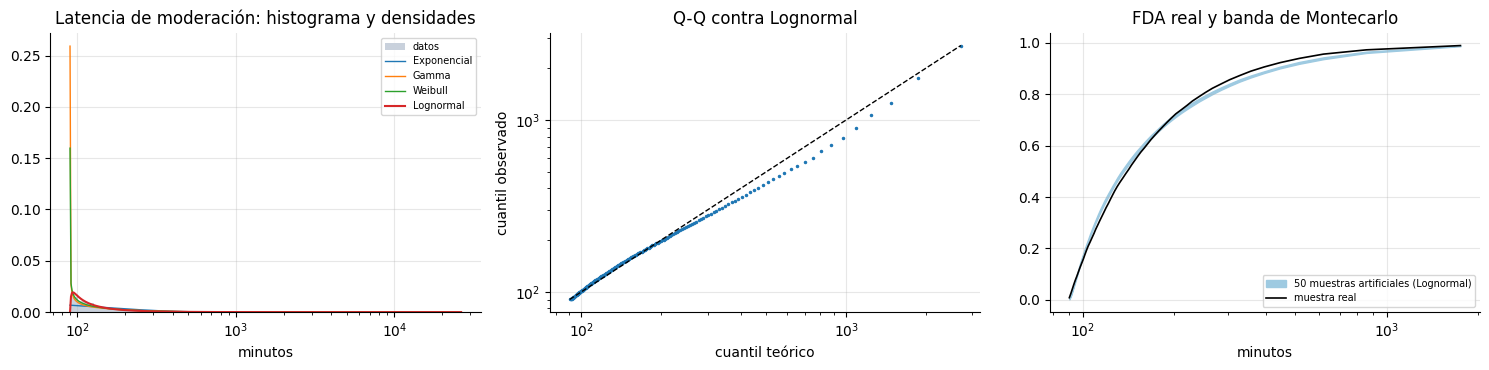

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Lognormal,"s=1.575, loc=89.99, escala=45.39",175716.8,0.0358,0.0392,0.0224,0.0
1,Weibull,"c=0.6549, loc=89.99, escala=97.19",177226.3,0.0574,0.0573,0.0221,0.0
2,Gamma,"a=0.5318, loc=89.99, escala=278.6",179921.8,0.1159,0.1172,0.0243,0.0
3,Exponencial,"loc=89.99, escala=148.2",185293.2,0.2191,0.2460,0.0279,0.0


**Latencia de moderación.** La candidata con menor AIC es **Lognormal** (s=1.575, loc=89.99, escala=45.39), con D = 0,039 en la submuestra contra un crítico de Montecarlo de 0,022 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

,cuantil,real,artificial p5,artificial mediana,artificial p95
0,10 %,96.30,95.83,96.04,96.27
1,25 %,108.30,105.30,105.74,106.22
2,50 %,140.30,134.24,135.41,136.55
3,75 %,215.90,217.53,221.28,225.47
4,90 %,379.42,419.65,431.70,444.76
5,99 %,1745.80,1723.41,1862.57,1996.83


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
Intercept,3.7935,0.0313,121.2420,0.0000,3.7321,3.8548
toxicity_index,0.0909,0.0671,1.3546,0.1756,-0.0407,0.2225
nociva,-0.0339,0.0269,-1.2598,0.2078,-0.0867,0.0189
verified_flag,0.0163,0.0384,0.4239,0.6716,-0.0590,0.0916


Piso: 90,0 minutos. Mediana 140,3 min, percentil 90 379 min, percentil 99 1.746 min. El R² de la latencia contra puntaje, nocividad y verificación es 0,0002: la demora no depende de esos atributos.

In [30]:
lat = df.loc[df.moderation_flag == 1, 'moderation_latency_min'].values
PISO = float(lat.min())
kw_lat = {'*': {'floc': PISO - 0.01}}
tabla_lat, aj_lat, mejor_lat = verificar_continua(lat, kw_extra=kw_lat, titulo='Latencia de moderación', unidad='minutos')
display(tabla_lat); conclusion(tabla_lat, 'Latencia de moderación')
display(cuantiles_artificiales(lat, *aj_lat[mejor_lat][:2]))
fl = df[df.moderation_flag == 1].assign(ll=lambda v: np.log(v.moderation_latency_min - PISO + 0.01))
reg_lat = smf.ols('ll ~ toxicity_index + nociva + verified_flag', data=fl).fit()
display(reg_lat.summary2().tables[1].round(4))
display(Markdown(f"Piso: {fmt(PISO, 1)} minutos. Mediana {fmt(np.median(lat), 1)} min, percentil 90 {fmt(np.quantile(lat, .9), 0)} min, percentil 99 {fmt(np.quantile(lat, .99), 0)} min. "
                 f"El R² de la latencia contra puntaje, nocividad y verificación es {fmt(reg_lat.rsquared, 4)}: la demora no depende de esos atributos."))

In [31]:
# ¿La acción corta la propagación? Se compara el instante de la primera acción de cada cascada con su último evento
df['accion'] = df.t + pd.to_timedelta(df.moderation_latency_min, unit='m')
primera = df[df.moderation_flag == 1].groupby('cascade_id').accion.min()
ultimo = df.groupby('cascade_id').t.max()
sigue = (ultimo[primera.index] > primera)
despues = df.merge(primera.rename('primera_accion'), left_on='cascade_id', right_index=True)
despues = despues[despues.t > despues.primera_accion]
display(Markdown(f"De las {fmt(len(primera))} cascadas con al menos un evento marcado, el {pct(sigue.mean())} sigue registrando reenvíos después de la primera acción, "
                 f"y {fmt(len(despues))} eventos ({pct(len(despues)/len(df))} de la muestra) ocurren después de esa acción. "
                 f"En los datos, la acción de moderación **no** corta la cascada: la muestra registra la propagación prácticamente sin remociones efectivas."))

De las 2.467 cascadas con al menos un evento marcado, el 53,0 % sigue registrando reenvíos después de la primera acción, y 28.247 eventos (42,8 % de la muestra) ocurren después de esa acción. En los datos, la acción de moderación **no** corta la cascada: la muestra registra la propagación prácticamente sin remociones efectivas.

### 5.10 Antigüedad de las cuentas

La consigna dice que las cuentas sospechadas de coordinación suelen ser nuevas (D12). Se ajusta la antigüedad por cuenta y luego se compara la de quienes participan en cascadas C2 con la del resto, con una prueba de permutación (Montecarlo sobre las etiquetas).

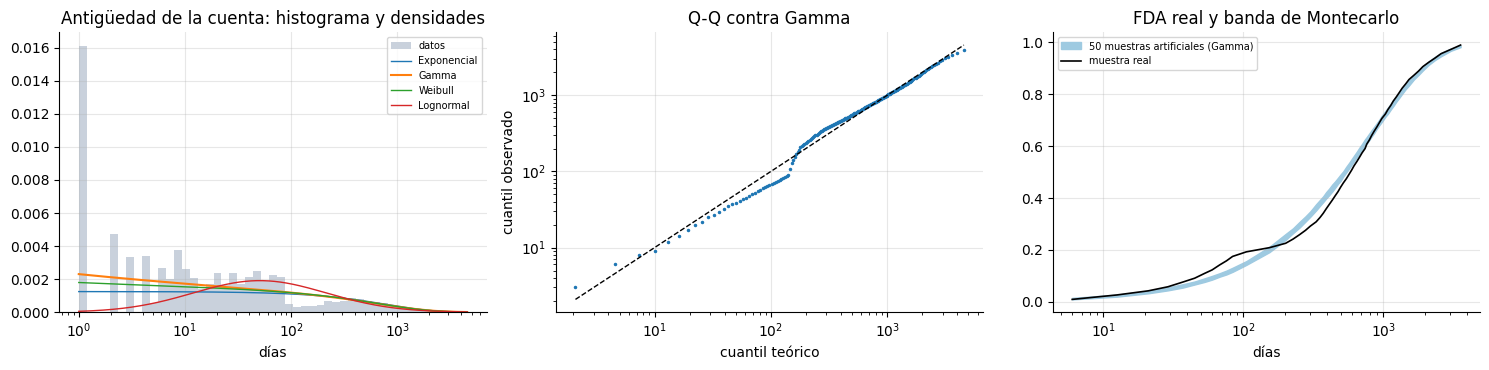

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Gamma,"a=0.8785, loc=0, escala=914.8",60964.6,0.0595,0.0618,0.0225,0.0
1,Weibull,"c=0.9396, loc=0, escala=782.5",60985.5,0.0672,0.0685,0.0232,0.0
2,Exponencial,"loc=0, escala=803.7",61008.1,0.0840,0.0937,0.0276,0.0
3,Lognormal,"s=1.448, loc=0, escala=412.3",61976.3,0.1339,0.1320,0.0227,0.0


**Antigüedad de la cuenta.** La candidata con menor AIC es **Gamma** (a=0.8785, loc=0, escala=914.8), con D = 0,062 en la submuestra contra un crítico de Montecarlo de 0,022 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

En cascadas C2, el 38,7 % de los eventos los hacen cuentas de menos de 90 días; en el resto, el 18,8 %. KS de dos muestras (submuestras de 3.000) = 0,196, contra un percentil 95 de permutación de 0,035 (p de Montecarlo = 0,000).

In [32]:
edad = cuentas.edad.dropna().values
tabla_edad, aj_edad, mejor_edad = verificar_continua(edad, titulo='Antigüedad de la cuenta', unidad='días')
display(tabla_edad); conclusion(tabla_edad, 'Antigüedad de la cuenta')
ev = df.dropna(subset=['account_age_days'])
a1 = ev.loc[ev.c2 == 1, 'account_age_days'].values; a0 = ev.loc[ev.c2 == 0, 'account_age_days'].values
D_obs = st.ks_2samp(a1, a0).statistic
todo = np.concatenate([a1, a0]); n1 = 3000
D_perm = []
for b in range(B_MC):
    pm = rng.permutation(todo); D_perm.append(st.ks_2samp(pm[:n1], pm[n1:n1 + 3000]).statistic)
sub1 = rng.choice(a1, n1, replace=False); sub0 = rng.choice(a0, 3000, replace=False)
D_sub = st.ks_2samp(sub1, sub0).statistic
display(Markdown(f"En cascadas C2, el {pct((a1 < 90).mean())} de los eventos los hacen cuentas de menos de 90 días; en el resto, el {pct((a0 < 90).mean())}. "
                 f"KS de dos muestras (submuestras de 3.000) = {fmt(D_sub, 3)}, contra un percentil 95 de permutación de {fmt(np.quantile(D_perm, .95), 3)} "
                 f"(p de Montecarlo = {fmt(float(np.mean(np.array(D_perm) >= D_sub)), 3)})."))

### 5.11 Campos que el modelo no usa

Se describen y ajustan igual, con menos réplicas, para dejar registrado su comportamiento y justificar que quedan fuera.

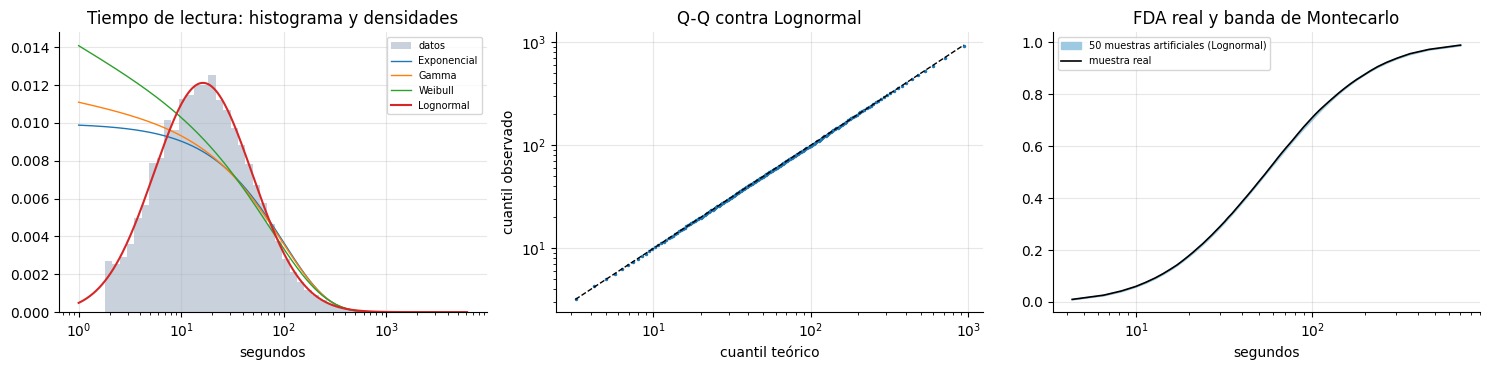

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Lognormal,"s=1.101, loc=0, escala=54.81",705907.1,0.0033,0.0195,0.0229,0.23
1,Weibull,"c=0.9123, loc=0, escala=95.05",715975.0,0.0631,0.0640,0.0211,0.00
2,Gamma,"a=0.9618, loc=0, escala=104.1",717045.2,0.0815,0.0900,0.0242,0.00
3,Exponencial,"loc=0, escala=100.2",717106.8,0.0866,0.0935,0.0273,0.00


**Tiempo de lectura.** La candidata con menor AIC es **Lognormal** (s=1.101, loc=0, escala=54.81), con D = 0,019 en la submuestra contra un crítico de Montecarlo de 0,023 (p de Montecarlo = 0,23). No se rechazan al 5 %: Lognormal.

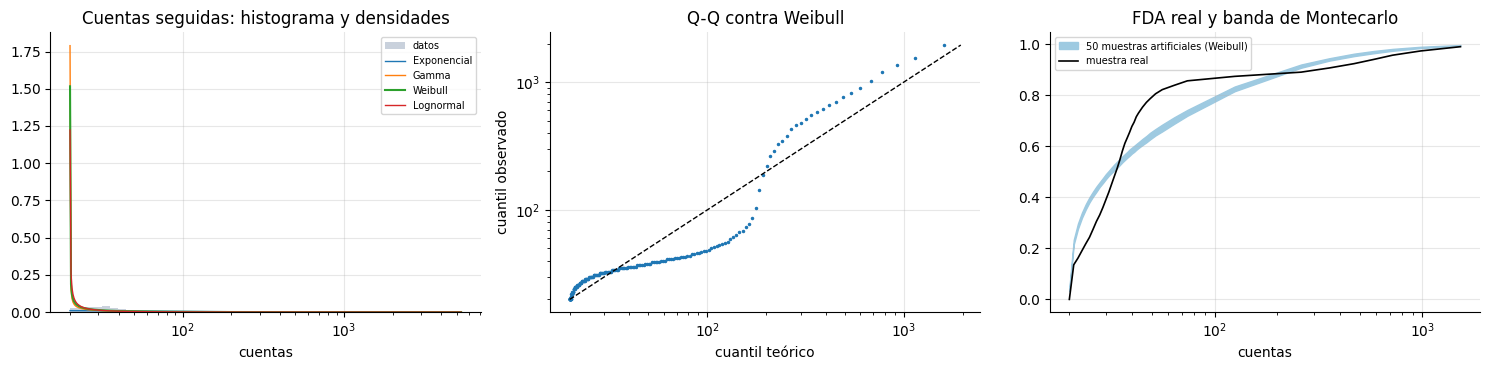

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,Weibull,"c=0.412, loc=19.99, escala=27.58",35255.7,0.1557,0.1590,0.0239,0.0
1,Lognormal,"s=3.007, loc=19.99, escala=7.107",35852.0,0.2105,0.2119,0.0240,0.0
2,Gamma,"a=0.2655, loc=19.99, escala=378.9",36057.2,0.2462,0.2513,0.0251,0.0
3,Exponencial,"loc=19.99, escala=100.6",44889.1,0.5450,0.5391,0.0241,0.0


**Cuentas seguidas (desplazadas a 20).** La candidata con menor AIC es **Weibull** (c=0.412, loc=19.99, escala=27.58), con D = 0,159 en la submuestra contra un crítico de Montecarlo de 0,024 (p de Montecarlo = 0,00). Ninguna candidata supera la verificación de Montecarlo al 5 %.

Correlación entre log(seguidores) y log(cuentas seguidas) por cuenta: 0,969.

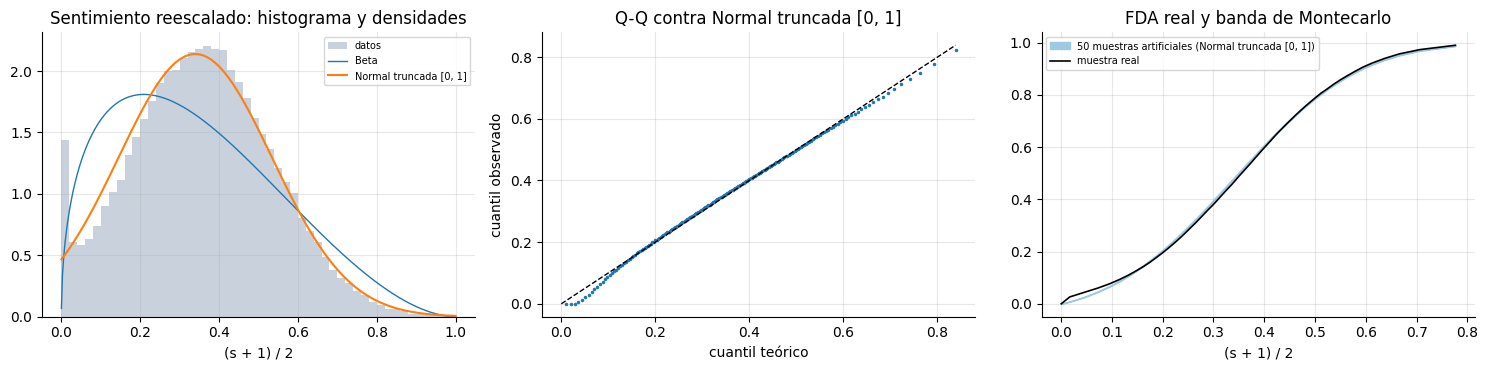

,candidata,parámetros (MLE),AIC,D muestra completa,D submuestra,D crítico MC 95 %,p Montecarlo
0,"Normal truncada [0, 1]","mu=0.3395, sigma=0.1945",-44168.2,0.0192,0.0258,0.0228,0.02
1,Beta,"a=1.485, b=2.836, loc=0, escala=1",-32000.4,0.1010,0.0947,0.0243,0.00


**Sentimiento.** La candidata con menor AIC es **Normal truncada [0, 1]** (mu=0.3395, sigma=0.1945), con D = 0,026 en la submuestra contra un crítico de Montecarlo de 0,023 (p de Montecarlo = 0,02). Ninguna candidata supera la verificación de Montecarlo al 5 %.

**likes** · media 65,37 · Lexis 3.981,6 · ceros 40,1 %

,candidata,parámetros,AIC,chi² submuestra,chi² crítico MC 95 %,p Montecarlo
0,Binomial negativa,"r=0.112, p=0.0017",388670.2,1.303200e+03,38.7,0.0
1,Geométrica,p=0.0151,684986.3,1.963240e+04,54.9,0.0
2,Poisson,media=65.367,26675253.6,2.405847e+36,0.0,0.0


**comments** · media 11,78 · Lexis 772,3 · ceros 68,6 %

,candidata,parámetros,AIC,chi² submuestra,chi² crítico MC 95 %,p Montecarlo
0,Binomial negativa,"r=0.067, p=0.0057",218450.5,399.8,26.6,0.0
1,Geométrica,p=0.0782,456621.6,11157.3,57.2,0.0
2,Poisson,media=11.782,4849772.4,407773824.7,0.0,0.0


In [33]:
x = df.dwell_time_sec.dropna().values; x = x[x > 0]
t_, a_, m_ = verificar_continua(x, B=B_MC_AUX, titulo='Tiempo de lectura', unidad='segundos'); display(t_); conclusion(t_, 'Tiempo de lectura')
x = cuentas.siguiendo.values
t_, a_, m_ = verificar_continua(x, B=B_MC_AUX, kw_extra={'*': {'floc': 19.99}}, titulo='Cuentas seguidas', unidad='cuentas'); display(t_); conclusion(t_, 'Cuentas seguidas (desplazadas a 20)')
display(Markdown(f"Correlación entre log(seguidores) y log(cuentas seguidas) por cuenta: {fmt(np.corrcoef(np.log(cuentas.seg), np.log(cuentas.siguiendo))[0, 1], 3)}."))
x = ((df.sentiment_score.dropna() + 1) / 2).clip(1e-4, 1 - 1e-4).values
t_, a_, m_ = verificar_continua(x, familias={'Beta': st.beta, 'Normal truncada [0, 1]': NormalTruncada01()}, kw_extra={'Beta': {'floc': 0, 'fscale': 1}}, B=B_MC_AUX, titulo='Sentimiento reescalado', log_x=False, unidad='(s + 1) / 2')
display(t_); conclusion(t_, 'Sentimiento')
for c in ['likes', 'comments']:
    x = df[c].dropna().values.astype(int)
    t_ = verificar_discreta(x, B=B_MC_AUX); display(Markdown(f'**{c}** · media {fmt(x.mean(), 2)} · Lexis {fmt(x.var() / x.mean(), 1)} · ceros {pct((x == 0).mean())}')); display(t_)

## 6. Relaciones entre variables

La lámina 12 de la Clase 06 pide preguntarse si dos o más variables se relacionan: si lo hacen, no son independientes, y el modelo tiene que generar una a partir de la otra. Todas las relaciones de esta sección son entre variables de entrada o atributos; ninguna usa variables de referencia, como exige la rúbrica.

### 6.1 Qué determina cuántos hijos tiene un reenvío

Se estima una regresión binomial negativa de los hijos de cada evento sobre los factores que la consigna menciona (D3, D4): nivel de audiencia, si es la semilla, la edad del evento medida en vidas medias de su pieza, la generación del reenvío dentro de la cascada, el formato, la superficie, la coordinación (C2), la verificación y si la pieza es nociva. Con enlace logarítmico, cada coeficiente exponenciado es un **factor multiplicativo sobre la media de hijos**. El parámetro de dispersión α se elige por verosimilitud perfilada.

Si la vida media del memo es literalmente la vida media del ritmo de reenvíos, la media de hijos tiene que caer como 2^(−edad/vida media), es decir, el coeficiente de la edad relativa tiene que valer −ln 2 ≈ −0,693. Se comparan dos modelos: sin la generación y con ella.

In [34]:
FORM = 'hijos ~ C(nivel, Treatment("nano")) + seed_flag + edad_rel + C(content_type_code, Treatment("IMG-MACRO")) + C(platform_surface_code, Treatment("DM")) + c2 + verified_flag + nociva'
FORM_G = FORM + ' + gen'
base_glm = dfc.dropna(subset=['edad_rel', 'nivel']).copy()
base_glm['gen'] = np.where(base_glm.seed_flag == 1, 0, base_glm.cascade_depth - 1)   # 0 para la semilla y la primera generación de reenvíos

def nb_perfilada(formula, datos, grilla=np.arange(0.5, 1.51, 0.02)):
    mejor = None
    for a in grilla:
        m = smf.glm(formula, data=datos, family=sm.families.NegativeBinomial(alpha=a)).fit()
        if mejor is None or m.llf > mejor[1].llf: mejor = (a, m)
    return mejor

alpha_sin, glm_sin = nb_perfilada(FORM, base_glm)
alpha_nb, glm_nb = nb_perfilada(FORM_G, base_glm)
display(Markdown(f"AIC sin la generación: {fmt(glm_sin.aic + 2, 1)}; con la generación: {fmt(glm_nb.aic + 2, 1)} (se suma 2 por α estimado). "
                 f"Diferencia: {fmt(glm_sin.aic - glm_nb.aic, 1)} a favor del modelo con generación."))
coef = glm_nb.params; ic = glm_nb.conf_int()
factores = pd.DataFrame({'coeficiente': coef, 'factor': np.exp(coef), 'IC 95 % inf.': np.exp(ic[0]), 'IC 95 % sup.': np.exp(ic[1]), 'p': glm_nb.pvalues})
factores.index = (factores.index.str.replace(r'C\((\w+), Treatment\("[^"]+"\)\)\[T\.', r'\1 = ', regex=True).str.replace(']', '', regex=False))
display(factores.round(4))
b_edad = coef['edad_rel']; ic_edad = ic.loc['edad_rel']
vm_efectiva = -np.log(2) / b_edad
display(Markdown(
    f"Dispersión α = {fmt(alpha_nb, 2)} (r = 1/α = {fmt(1/alpha_nb, 2)}; r = 1 es la geométrica). "
    f"Coeficiente de la edad relativa: {fmt(b_edad, 3)} (IC 95 %: {fmt(ic_edad[0], 3)} a {fmt(ic_edad[1], 3)}) contra −0,693 del decaimiento con vida media exacta: "
    f"el ritmo se reduce a la mitad cada {fmt(vm_efectiva, 2)} vidas medias declaradas (sin la generación en el modelo, el coeficiente era {fmt(glm_sin.params['edad_rel'], 3)}). "
    f"Además, cada generación multiplica la media de hijos por {fmt(np.exp(coef['gen']), 3)}, con independencia de la edad. "
    f"El coeficiente de pieza nociva es {fmt(coef['nociva'], 3)} (p = {fmt(glm_nb.pvalues['nociva'], 3)}): con el resto constante, "
    f"{'el contenido nocivo no se reenvía distinto que el legítimo' if glm_nb.pvalues['nociva'] > 0.05 else 'el contenido nocivo se reenvía distinto que el legítimo'}."
))

AIC sin la generación: 129.047,3; con la generación: 128.326,0 (se suma 2 por α estimado). Diferencia: 721,3 a favor del modelo con generación.

,coeficiente,factor,IC 95 % inf.,IC 95 % sup.,p
Intercept,-0.8019,0.4485,0.4248,0.4735,0.0000
nivel = micro,0.4948,1.6402,1.5621,1.7223,0.0000
nivel = macro,1.5663,4.7891,4.5642,5.0251,0.0000
nivel = mega,1.9702,7.1722,6.7845,7.5820,0.0000
content_type_code = LINK-EXT,-0.5557,0.5736,0.5385,0.6111,0.0000
content_type_code = POLL,-0.2895,0.7486,0.6982,0.8026,0.0000
content_type_code = SCREENSHOT,-0.2020,0.8171,0.7782,0.8579,0.0000
content_type_code = TXT,-0.3909,0.6764,0.6466,0.7076,0.0000
content_type_code = VID-SHORT,0.0920,1.0964,1.0643,1.1294,0.0000
platform_surface_code = FEED,0.5020,1.6521,1.5711,1.7372,0.0000


Dispersión α = 0,80 (r = 1/α = 1,25; r = 1 es la geométrica). Coeficiente de la edad relativa: -0,678 (IC 95 %: -0,706 a -0,650) contra −0,693 del decaimiento con vida media exacta: el ritmo se reduce a la mitad cada 1,02 vidas medias declaradas (sin la generación en el modelo, el coeficiente era -0,765). Además, cada generación multiplica la media de hijos por 0,900, con independencia de la edad. El coeficiente de pieza nociva es -0,012 (p = 0,380): con el resto constante, el contenido nocivo no se reenvía distinto que el legítimo.

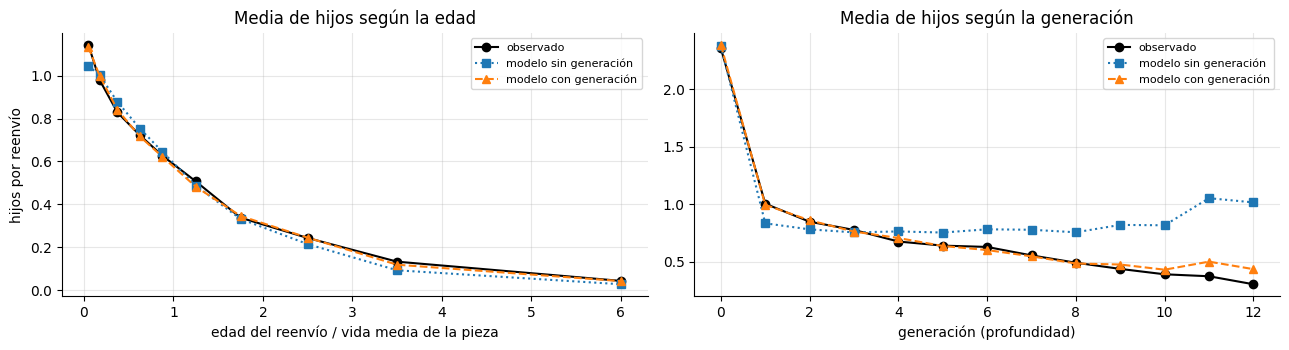

,sin truncadas,con truncadas,cambio %
Intercept,0.448,0.454,1.249
nivel = micro,1.640,1.633,-0.411
nivel = macro,4.789,4.897,2.260
nivel = mega,7.172,7.375,2.824
content_type_code = LINK-EXT,0.574,0.574,-0.002
content_type_code = POLL,0.749,0.760,1.555
content_type_code = SCREENSHOT,0.817,0.811,-0.725
content_type_code = TXT,0.676,0.679,0.429
content_type_code = VID-SHORT,1.096,1.078,-1.639
platform_surface_code = FEED,1.652,1.662,0.601


In [35]:
# Curva de decaimiento: media observada de hijos por edad relativa contra la predicción del modelo
cortes = [0, .1, .25, .5, .75, 1, 1.5, 2, 3, 4, 8]
base_glm['pred_sin'] = glm_sin.predict(base_glm); base_glm['pred_con'] = glm_nb.predict(base_glm)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
grp = pd.cut(base_glm.edad_rel, cortes)
t_ = base_glm.groupby(grp, observed=True)[['hijos', 'pred_sin', 'pred_con']].mean()
xm = [(a.left + a.right) / 2 for a in t_.index]
ax[0].plot(xm, t_.hijos, 'ko-', label='observado'); ax[0].plot(xm, t_.pred_sin, 's:', label='modelo sin generación'); ax[0].plot(xm, t_.pred_con, '^--', label='modelo con generación')
ax[0].set_xlabel('edad del reenvío / vida media de la pieza'); ax[0].set_ylabel('hijos por reenvío'); ax[0].set_title('Media de hijos según la edad'); ax[0].legend(fontsize=8)
t2 = base_glm[base_glm.cascade_depth <= 12].groupby('cascade_depth')[['hijos', 'pred_sin', 'pred_con']].mean()
ax[1].plot(t2.index, t2.hijos, 'ko-', label='observado'); ax[1].plot(t2.index, t2.pred_sin, 's:', label='modelo sin generación'); ax[1].plot(t2.index, t2.pred_con, '^--', label='modelo con generación')
ax[1].set_xlabel('generación (profundidad)'); ax[1].set_title('Media de hijos según la generación'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Sensibilidad: el mismo modelo incluyendo las cascadas truncadas
base_todo = df.dropna(subset=['edad_rel', 'nivel']).copy(); base_todo['gen'] = np.where(base_todo.seed_flag == 1, 0, base_todo.cascade_depth - 1)
glm_todo = smf.glm(FORM_G, data=base_todo, family=sm.families.NegativeBinomial(alpha=alpha_nb)).fit()
comp = pd.DataFrame({'sin truncadas': np.exp(glm_nb.params), 'con truncadas': np.exp(glm_todo.params)})
comp['cambio %'] = 100 * (comp['con truncadas'] / comp['sin truncadas'] - 1)
comp.index = factores.index
display(comp.round(3))

### 6.2 Seguidores, hijos e impresiones

La consigna anticipa que cien veces más seguidores no dan cien veces más reenvíos (D6). La forma natural de verlo es una relación potencial y = a·x^b, que en escala log-log es una recta de pendiente b (DROSG p. 150).

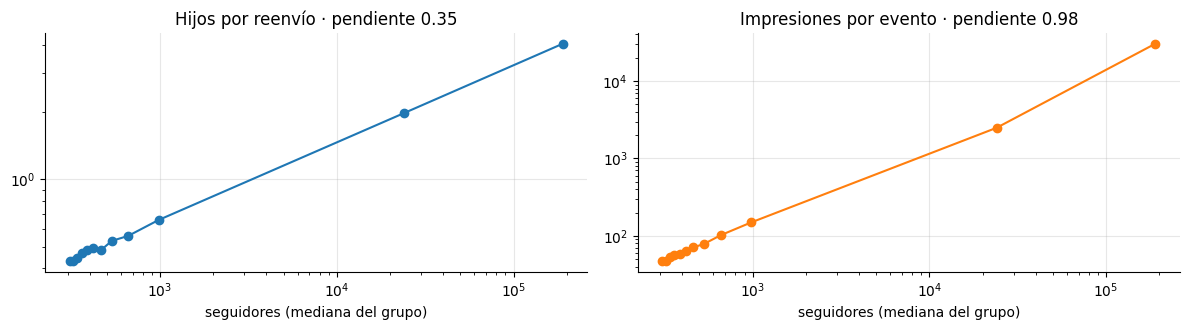

Pendiente log-log de hijos contra seguidores: **0,35** (sublineal, como dice el memo). Pendiente de impresiones contra seguidores: **0,98** (prácticamente proporcional). El alcance escala con la audiencia, pero la propensión a reenviar no: por eso el modelo usa niveles de audiencia para los hijos y una fracción de los seguidores para las impresiones.

In [36]:
q = pd.qcut(np.log10(dfc.actor_follower_count), 12, duplicates='drop')
g = dfc.groupby(q, observed=True).agg(seg=('actor_follower_count', 'median'), hijos=('hijos', 'mean'), imp=('impressions', 'median'))
b_h = np.polyfit(np.log10(g.seg), np.log10(g.hijos), 1); b_i = np.polyfit(np.log10(g.seg), np.log10(g.imp), 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].loglog(g.seg, g.hijos, 'o-'); ax[0].set_title(f'Hijos por reenvío · pendiente {b_h[0]:.2f}'); ax[0].set_xlabel('seguidores (mediana del grupo)')
ax[1].loglog(g.seg, g.imp, 'o-', color='C1'); ax[1].set_title(f'Impresiones por evento · pendiente {b_i[0]:.2f}'); ax[1].set_xlabel('seguidores (mediana del grupo)')
plt.tight_layout(); plt.show()
display(Markdown(f"Pendiente log-log de hijos contra seguidores: **{fmt(b_h[0], 2)}** (sublineal, como dice el memo). "
                 f"Pendiente de impresiones contra seguidores: **{fmt(b_i[0], 2)}** (prácticamente proporcional). "
                 f"El alcance escala con la audiencia, pero la propensión a reenviar no: por eso el modelo usa niveles de audiencia para los hijos y una fracción de los seguidores para las impresiones."))

### 6.3 Nivel de audiencia de los hijos

Si el nivel del hijo dependiera del nivel del padre (las cuentas grandes reenviando entre sí, por ejemplo), el modelo tendría que llevar una matriz de transición entre niveles. Se prueba la independencia con chi-cuadrado y su p-valor por permutación.

In [37]:
padre = dfc.set_index('event_id').nivel
hij = dfc[dfc.seed_flag == 0].assign(nivel_padre=lambda v: v.parent_event_id.map(padre)).dropna(subset=['nivel', 'nivel_padre'])
tab = pd.crosstab(hij.nivel_padre, hij.nivel)
display((tab.div(tab.sum(1), axis=0)).round(3))
chi_obs = st.chi2_contingency(tab)[0]
perm = [st.chi2_contingency(pd.crosstab(hij.nivel_padre.values, rng.permutation(hij.nivel.values)))[0] for _ in range(B_MC)]
p_nivel = float(np.mean(np.array(perm) >= chi_obs))
mix_hijos = hij.nivel.value_counts(normalize=True).reindex(NIVELES)
display(Markdown(f"Chi-cuadrado = {fmt(chi_obs, 1)}; p por permutación = {fmt(p_nivel, 3)}. "
                 f"{'No hay evidencia de dependencia' if p_nivel > 0.05 else 'Hay evidencia de dependencia'} entre el nivel del padre y el del hijo. "
                 f"Distribución del nivel de los hijos: " + ', '.join(f'{k} {pct(v)}' for k, v in mix_hijos.items()) + "."))

nivel,nano,micro,macro,mega
nivel_padre,,,,
nano,0.820,0.066,0.060,0.054
micro,0.821,0.065,0.064,0.050
macro,0.813,0.069,0.062,0.056
mega,0.811,0.066,0.064,0.059


Chi-cuadrado = 12,2; p por permutación = 0,210. No hay evidencia de dependencia entre el nivel del padre y el del hijo. Distribución del nivel de los hijos: nano 81,5 %, micro 6,7 %, macro 6,2 %, mega 5,6 %.

### 6.4 Verificación y nivel de audiencia; coordinación y semilla

In [38]:
p_verif = df.groupby('nivel', observed=True).verified_flag.mean()
semillas = pieza.dropna(subset=['nivel'])
nivel_sem = pd.crosstab(semillas.c2, semillas.nivel, normalize='index').reindex(columns=NIVELES)
huellas = df.dropna(subset=['device_fingerprint_code']).groupby('device_fingerprint_code').actor_id.nunique()
display(Markdown("**Probabilidad de cuenta verificada por nivel:** " + ', '.join(f'{k} {pct(v)}' for k, v in p_verif.items()) + "."))
display(Markdown("**Nivel de la cuenta semilla según coordinación (filas: C2 = 0 y 1):**")); display(nivel_sem.round(3))
display(Markdown(f"Huellas de dispositivo compartidas por más de una cuenta: {fmt(int((huellas > 1).sum()))} de {fmt(len(huellas))}. "
                 f"Factor de C2 sobre la media de hijos (6.1): {fmt(factores.loc['c2', 'factor'], 2)}. "
                 f"Las cascadas C2 tienen tamaño medio {fmt(pieza[pieza.c2 == 1].tamano.mean(), 1)} contra {fmt(pieza[pieza.c2 == 0].tamano.mean(), 1)} del resto."))

**Probabilidad de cuenta verificada por nivel:** nano 2,4 %, micro 10,8 %, macro 61,1 %, mega 88,9 %.

**Nivel de la cuenta semilla según coordinación (filas: C2 = 0 y 1):**

nivel,nano,micro,macro,mega
c2,,,,
0,0.555,0.075,0.153,0.217
1,0.649,0.070,0.115,0.166


Huellas de dispositivo compartidas por más de una cuenta: 11 de 3.989. Factor de C2 sobre la media de hijos (6.1): 1,79. Las cascadas C2 tienen tamaño medio 42,8 contra 9,8 del resto.

### 6.5 Independencia entre los atributos de una pieza y en el tiempo

Antes de generar los atributos de cada pieza por separado hay que comprobar que no estén relacionados (LAW p. 335). Se calcula la correlación de Spearman entre los atributos numéricos de la semilla, y la autocorrelación de las vidas medias en el orden de llegada, que tendría que ser nula si las piezas son independientes entre sí.

In [39]:
at = pieza.assign(log_seg=np.log10(pieza.actor_follower_count), hora=pieza.t.dt.hour)[['content_half_life_min', 'toxicity_index', 'log_seg', 'c2', 'nociva', 'hora', 'verified_flag']]
display(at.corr(method='spearman').round(3))
serie = pieza.sort_values('t').content_half_life_min.dropna().values
ac = [np.corrcoef(serie[:-k], serie[k:])[0, 1] for k in range(1, 11)]
display(Markdown(f"Autocorrelación de la vida media en el orden de llegada, rezagos 1 a 10: " + ', '.join(fmt(a, 3) for a in ac) +
                 f". Banda aproximada de ruido: ±{fmt(2 / np.sqrt(len(serie)), 3)}."))

,content_half_life_min,toxicity_index,log_seg,c2,nociva,hora,verified_flag
content_half_life_min,1.000,-0.008,-0.016,-0.024,-0.001,0.007,0.014
toxicity_index,-0.008,1.000,0.000,-0.001,0.380,0.016,0.001
log_seg,-0.016,0.000,1.000,-0.050,-0.022,-0.020,0.731
c2,-0.024,-0.001,-0.050,1.000,-0.010,0.011,-0.068
nociva,-0.001,0.380,-0.022,-0.010,1.000,0.013,-0.007
hora,0.007,0.016,-0.020,0.011,0.013,1.000,-0.012
verified_flag,0.014,0.001,0.731,-0.068,-0.007,-0.012,1.000


Autocorrelación de la vida media en el orden de llegada, rezagos 1 a 10: -0,002, 0,002, 0,020, 0,012, -0,009, -0,012, -0,021, -0,010, 0,036, 0,004. Banda aproximada de ruido: ±0,028.

## 7. Verificación integral: cascadas simuladas contra cascadas observadas

Las secciones 5 y 6 verifican cada distribución por separado. Falta la prueba más exigente: que **juntas** reproduzcan las cascadas observadas, que es la condición de aceptación de RedBaires (RN5: forma y dispersión parecidas). Se generan muestras artificiales de 5.000 cascadas con las distribuciones y relaciones ajustadas, se cortan en el mismo tope que la muestra y se comparan.

Se simulan dos versiones del mismo proceso:

- **Por evento:** cada reenvío sortea sus hijos con la binomial negativa de 6.1, su superficie, su verificación y su retardo. Es la forma más fiel, pero el número de eventos crece con la cascada.
- **Agregada por generación:** es la arquitectura del modelo conceptual. La pieza lleva un contador de reenvíos por nivel y, en cada generación, los hijos de los n reenvíos de un nivel se sortean de una sola vez, usando que la suma de n binomiales negativas de parámetros (r, p) es una binomial negativa (n·r, p) (LAW p. 329 y p. 488). La memoria por pieza no depende del tamaño de la cascada.

La versión agregada tiene una dificultad: los reenvíos de una misma generación no tienen todos la misma edad, y el decaimiento 2^(−edad/vida media) es convexo, así que aplicarlo a la edad promedio de la generación sobreestima el envejecimiento (desigualdad de Jensen) y achica las cascadas. Se prueban dos formas de representar la edad de una generación:

- **Edad media:** un solo número por generación.
- **Partículas:** una muestra fija de 30 edades por pieza. En cada generación, las 30 edades de los hijos se obtienen eligiendo padres entre las 30 anteriores con probabilidad proporcional a su propensión a reenviar y sumándoles un retardo sorteado. El decaimiento que se aplica es el promedio sobre las 30 edades. La memoria sigue siendo fija: 4 contadores y 30 edades por pieza.

Si la versión agregada reproduce los datos tan bien como la versión por evento, la arquitectura queda respaldada por los datos y no solo por la restricción del memo.

In [40]:
# ---- insumos ajustados ----
b = glm_nb.params; r_nb = 1 / alpha_nb
def coef_cat(prefijo, valor):
    k = [i for i in b.index if i.startswith(prefijo) and i.endswith(f'[T.{valor}]')]
    return float(b[k[0]]) if k else 0.0
B_NIV = np.array([coef_cat('C(nivel', nv) for nv in NIVELES])
form_vals = pieza.content_type_code.value_counts(normalize=True)
B_FORM = {f: coef_cat('C(content_type', f) for f in form_vals.index}
surf = dfc[dfc.seed_flag == 0].platform_surface_code.value_counts(normalize=True)
B_SURF = np.array([coef_cat('C(platform_surface', s) for s in surf.index]); P_SURF = surf.values
P_VER = p_verif.reindex(NIVELES).values
P_HIJO = mix_hijos.values
P_C2 = pieza.c2.mean()
P_NIV_SEM = {c: nivel_sem.loc[c].values for c in [0, 1]}
d_vm, p_vm, _ = aj_vm[mejor_vm]
P_NOC = pieza.nociva.mean()

def sortear_piezas(n):
    c2 = (rng.random(n) < P_C2).astype(int)
    niv = np.where(c2 == 1, rng.choice(4, n, p=P_NIV_SEM[1]), rng.choice(4, n, p=P_NIV_SEM[0]))
    form = rng.choice(form_vals.index.values, n, p=form_vals.values)
    lin = b['Intercept'] + np.array([B_FORM[f] for f in form]) + b['c2'] * c2 + b['nociva'] * (rng.random(n) < P_NOC)
    vm = d_vm.rvs(*p_vm, size=n, random_state=rng)
    return niv, lin, vm

def sim_evento(n_casc, tope):
    niv0, lin, vm = sortear_piezas(n_casc)
    tam = np.ones(n_casc, int); prof = np.zeros(n_casc, int); dur = np.zeros(n_casc)
    casc = np.arange(n_casc); niv = niv0; edad = np.zeros(n_casc)
    g = 0
    while len(casc) and g < 80:
        sup = rng.choice(len(P_SURF), len(casc), p=P_SURF); ver = rng.random(len(casc)) < P_VER[niv]
        mu = np.exp(lin[casc] + B_NIV[niv] + b['seed_flag'] * (g == 0) + b['gen'] * max(g - 1, 0) + b['edad_rel'] * edad / vm[casc] + B_SURF[sup] + b['verified_flag'] * ver)
        k = rng.negative_binomial(r_nb, r_nb / (r_nb + mu))
        k[tam[casc] >= tope] = 0
        casc = np.repeat(casc, k); edad = np.repeat(edad, k) + d_ret.rvs(*p_ret, size=k.sum(), random_state=rng)
        niv = rng.choice(4, len(casc), p=P_HIJO)
        np.add.at(tam, casc, 1); g += 1
        prof[np.unique(casc)] = g; np.maximum.at(dur, casc, edad)
    return np.minimum(tam, tope), prof, dur / 60

LOG_SURF = np.log(np.sum(P_SURF * np.exp(B_SURF)))
LOG_VER = np.log(1 + P_VER * (np.exp(b['verified_flag']) - 1))
M_PART = 30
def sim_agregada(n_casc, tope, particulas=True):
    niv0, lin, vm = sortear_piezas(n_casc)
    n = np.zeros((n_casc, 4)); n[np.arange(n_casc), niv0] = 1
    tam = np.ones(n_casc); prof = np.zeros(n_casc, int); dur = np.zeros(n_casc)
    part = np.zeros((n_casc, M_PART)); g = 0
    while n.sum() > 0 and g < 80:
        dec_part = np.exp(b['edad_rel'] * part / vm[:, None])
        dec = dec_part.mean(1) if particulas else np.exp(b['edad_rel'] * part.mean(1) / vm)
        mu = np.exp(lin[:, None] + B_NIV[None, :] + b['seed_flag'] * (g == 0) + b['gen'] * max(g - 1, 0) + LOG_SURF + LOG_VER[None, :]) * dec[:, None]
        hijos = np.where(n > 0, rng.negative_binomial(np.maximum(n * r_nb, 1e-9), r_nb / (r_nb + mu)), 0).sum(1)
        hijos = np.where(tam >= tope, 0, hijos)
        # edades de la generación siguiente: padres elegidos por propensión + retardo
        w = dec_part / dec_part.sum(1, keepdims=True)
        idx = np.minimum((rng.random((n_casc, M_PART))[:, :, None] > np.cumsum(w, 1)[:, None, :]).sum(2), M_PART - 1)
        part = np.take_along_axis(part, idx, 1) + d_ret.rvs(*p_ret, size=n_casc * M_PART, random_state=rng).reshape(n_casc, M_PART)
        n = rng.multinomial(hijos.astype(int), P_HIJO).astype(float)
        vivos = hijos > 0; g += 1
        # instante del último evento de la generación: cuantil n/(n+1) de las edades (máximo esperado de n reenvíos)
        srt = np.sort(part, 1); q = hijos / (hijos + 1); fila = np.round(q * (M_PART - 1)).astype(int)
        tam = tam + hijos; prof[vivos] = g; dur = np.where(vivos, np.maximum(dur, srt[np.arange(n_casc), fila]), dur)
    return np.minimum(tam, tope), prof, dur / 60

,tamaño ≥,observado,por evento p5,por evento mediana,por evento p95,agregada con partículas p5,agregada con partículas mediana,agregada con partículas p95,agregada con edad media p5,agregada con edad media mediana,agregada con edad media p95
0,2,0.5962,0.5811,0.5957,0.6102,0.5905,0.5967,0.6078,0.5902,0.6022,0.6113
1,5,0.3470,0.3440,0.3529,0.3665,0.3412,0.3543,0.3693,0.3414,0.3502,0.3614
2,10,0.2372,0.2236,0.2297,0.2391,0.2222,0.2320,0.2431,0.2186,0.2241,0.2325
3,20,0.1428,0.1296,0.1380,0.1440,0.1288,0.1386,0.1469,0.1213,0.1272,0.1330
4,50,0.0570,0.0533,0.0552,0.0578,0.0471,0.0552,0.0614,0.0449,0.0484,0.0516
5,100,0.0236,0.0208,0.0232,0.0256,0.0191,0.0220,0.0263,0.0171,0.0202,0.0217
6,200,0.0098,0.0084,0.0097,0.0127,0.0072,0.0086,0.0116,0.0068,0.0079,0.0100
7,500,0.0028,0.0025,0.0034,0.0042,0.0020,0.0030,0.0048,0.0016,0.0028,0.0044


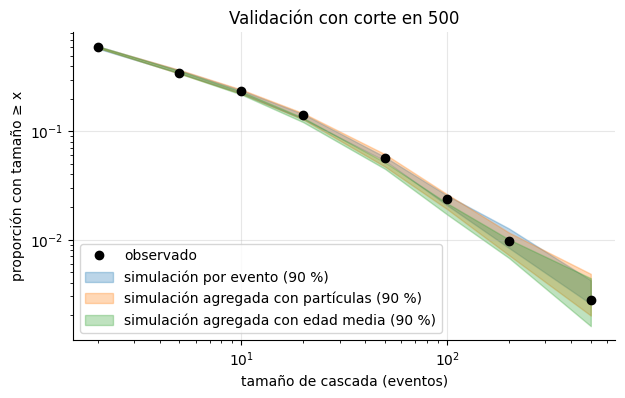

,tamaño medio,duración mediana (h),duración p90 (h),profundidad máxima,profundidad p99
por evento,13.33,0.97,9.46,16.0,10.0
agregada con partículas,13.15,0.93,5.32,16.0,10.0
agregada con edad media,12.27,0.93,5.11,15.5,10.0
observado,13.20,0.94,8.92,15.0,10.0


In [41]:
R_SIM = 20
obs_tam = pieza.tamano.values; obs_prof = df.groupby('cascade_id').cascade_depth.max().values
obs_dur = (df.groupby('cascade_id').edad_min.max() / 60).dropna().values
umbrales = [2, 5, 10, 20, 50, 100, 200, TOPE]
def ccdf(v): return np.array([(v >= u).mean() for u in umbrales])
VERSIONES = [('por evento', sim_evento), ('agregada con partículas', sim_agregada), ('agregada con edad media', lambda n, t: sim_agregada(n, t, particulas=False))]
res = {k: [] for k, _ in VERSIONES}
extra = {k: [] for k, _ in VERSIONES}
for _ in range(R_SIM):
    for nombre, f in VERSIONES:
        t_, p_, d_ = f(len(obs_tam), TOPE)
        res[nombre].append(ccdf(t_)); extra[nombre].append([t_.mean(), np.median(d_), np.quantile(d_, .9), p_.max(), np.quantile(p_, .99)])
tabla_val = pd.DataFrame({'tamaño ≥': umbrales, 'observado': ccdf(obs_tam)})
for nombre in res:
    a = np.array(res[nombre])
    tabla_val[f'{nombre} p5'] = np.quantile(a, .05, 0); tabla_val[f'{nombre} mediana'] = np.median(a, 0); tabla_val[f'{nombre} p95'] = np.quantile(a, .95, 0)
display(tabla_val.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(umbrales, ccdf(obs_tam), 'ko', label='observado')
for (nombre, _), col in zip(VERSIONES, ['C0', 'C1', 'C2']):
    a = np.array(res[nombre]); ax.fill_between(umbrales, np.quantile(a, .05, 0), np.quantile(a, .95, 0), alpha=.3, color=col, label=f'simulación {nombre} (90 %)')
ax.set_xlabel('tamaño de cascada (eventos)'); ax.set_ylabel('proporción con tamaño ≥ x'); ax.set_title(f'Validación con corte en {TOPE}'); ax.legend(); plt.show()

ext = pd.DataFrame({k: np.median(np.array(v), 0) for k, v in extra.items()}, index=['tamaño medio', 'duración mediana (h)', 'duración p90 (h)', 'profundidad máxima', 'profundidad p99']).T
ext.loc['observado'] = [obs_tam.mean(), np.median(obs_dur), np.quantile(obs_dur, .9), obs_prof.max(), np.quantile(obs_prof, .99)]
display(ext.round(2))

In [42]:
def dentro(nombre):
    a = np.array(res[nombre]); o = ccdf(obs_tam)
    return int(((o >= np.quantile(a, .05, 0)) & (o <= np.quantile(a, .95, 0))).sum())
def dif(a, b_):
    A = np.median(np.array(res[a]), 0); Bm = np.median(np.array(res[b_]), 0); return np.max(np.abs(A - Bm) / Bm)
display(Markdown(
    f"De los {len(umbrales)} puntos de la curva de tamaños, el observado cae dentro de la banda de Montecarlo del 90 % en {dentro('por evento')} para la simulación por evento, "
    f"en {dentro('agregada con partículas')} para la agregada con partículas y en {dentro('agregada con edad media')} para la agregada con edad media. "
    f"La mayor diferencia relativa entre las medianas de la versión por evento y la agregada con partículas es {pct(dif('agregada con partículas', 'por evento'))}; "
    f"con edad media, {pct(dif('agregada con edad media', 'por evento'))}, siempre por defecto en la cola: es el sesgo de Jensen descripto arriba. "
    f"La versión agregada con partículas usa una entidad por pieza, cuatro contadores y {M_PART} edades, cualquiera sea el tamaño de la cascada. "
    f"Duración: percentil 90 de {fmt(ext.loc['agregada con partículas', 'duración p90 (h)'], 1)} h en la agregada, {fmt(ext.loc['por evento', 'duración p90 (h)'], 1)} h por evento "
    f"y {fmt(ext.loc['observado', 'duración p90 (h)'], 1)} h observado: la versión agregada reproduce el tamaño mejor que la duración de las cascadas largas, "
    f"porque resume cada generación en 30 edades y una rama lenta puede quedar fuera de la muestra."
))

De los 8 puntos de la curva de tamaños, el observado cae dentro de la banda de Montecarlo del 90 % en 8 para la simulación por evento, en 8 para la agregada con partículas y en 4 para la agregada con edad media. La mayor diferencia relativa entre las medianas de la versión por evento y la agregada con partículas es 11,8 %; con edad media, 18,6 %, siempre por defecto en la cola: es el sesgo de Jensen descripto arriba. La versión agregada con partículas usa una entidad por pieza, cuatro contadores y 30 edades, cualquiera sea el tamaño de la cascada. Duración: percentil 90 de 5,3 h en la agregada, 9,5 h por evento y 8,9 h observado: la versión agregada reproduce el tamaño mejor que la duración de las cascadas largas, porque resume cada generación en 30 edades y una rama lenta puede quedar fuera de la muestra.

## 7.5 Insumos para la evaluación a priori

La rúbrica pide estimar el resultado esperado con una simplificación del problema y una resolución analítica sencilla, sin simular, aplicando la teoría de la materia. Los datos permiten dos cálculos de ese tipo.

**Tamaño esperado de una cascada (proceso de ramificación).** Si cada reenvío tiene en promedio m hijos y la semilla m₀, el tamaño esperado de un proceso de Galton-Watson subcrítico es 1 + m₀/(1 − m). La simplificación ignora la edad, la generación y la heterogeneidad entre niveles, que se absorben en los promedios.

**Fila de moderación (M/M/1).** Con un moderador por turno y disciplina FIFO, el tiempo medio en el sistema es W = 1/(μ − λ) (BANKS-DES p. 252; ANDERSON p. 8). La latencia observada menos el piso fijo estima W. El tiempo de revisión no está en los datos, pero si el costo de revisar un ítem se interpreta como tiempo de moderador (costo por ítem dividido costo por hora), da un tiempo de servicio, y con eso se despeja la tasa de llegada λ y la ocupación ρ que explicarían la latencia observada.

In [43]:
m0 = dfc[dfc.seed_flag == 1].hijos.mean(); m1 = dfc[dfc.seed_flag == 0].hijos.mean()
tam_gw = 1 + m0 / (1 - m1)
display(Markdown(f"m₀ = {fmt(m0, 3)}, m = {fmt(m1, 3)} → tamaño esperado {fmt(tam_gw, 2)} eventos por cascada, contra {fmt(obs_tam.mean(), 2)} observado (con corte en {TOPE}). "
                 f"Si m subiera a 0,95, el tamaño esperado pasaría a {fmt(1 + m0 / (1 - 0.95), 1)}: cerca de m = 1 una diferencia chica en R cambia mucho el tamaño, que es la idea central del escenario pesimista."))
costo_item = float(par.set_index('param').loc['costo_revision_por_item_flag', 'valor_base']); costo_h = float(par.set_index('param').loc['costo_moderador_por_hora', 'valor_base'])
ts_min = costo_item / costo_h * 60; mu = 1 / ts_min
W = (lat - PISO).mean(); lam_mm1 = mu - 1 / W; rho = lam_mm1 / mu
piezas_marcadas_dia = df[df.moderation_flag == 1].cascade_id.nunique() / n_dias
display(Markdown(
    f"Tiempo de revisión implícito: {fmt(costo_item, 2)} USD por ítem ÷ {fmt(costo_h, 0)} USD por hora = {fmt(ts_min, 3)} min ({fmt(ts_min * 60, 0)} s). "
    f"Latencia media por encima del piso: W = {fmt(W, 1)} min. Con M/M/1: λ = μ − 1/W = {fmt(lam_mm1, 3)} ítems por minuto, ocupación ρ = {fmt(rho, 4)}, "
    f"es decir {fmt(lam_mm1 * 60 * 24, 0)} ítems por día para un moderador. En la muestra hay {fmt(piezas_marcadas_dia, 1)} piezas marcadas por día: "
    f"si esta lectura es correcta, la muestra representa del orden de 1 de cada {fmt(lam_mm1 * 60 * 24 / piezas_marcadas_dia, 0)} piezas marcadas de la plataforma. "
    f"Es una estimación a priori frágil (depende de interpretar el costo por ítem como tiempo), pero muestra que la fila actual estaría al borde de la saturación."
))

m₀ = 2,346, m = 0,784 → tamaño esperado 11,84 eventos por cascada, contra 13,20 observado (con corte en 500). Si m subiera a 0,95, el tamaño esperado pasaría a 47,9: cerca de m = 1 una diferencia chica en R cambia mucho el tamaño, que es la idea central del escenario pesimista.

Tiempo de revisión implícito: 0,12 USD por ítem ÷ 22 USD por hora = 0,327 min (20 s). Latencia media por encima del piso: W = 148,2 min. Con M/M/1: λ = μ − 1/W = 3,049 ítems por minuto, ocupación ρ = 0,9978, es decir 4.390 ítems por día para un moderador. En la muestra hay 13,7 piezas marcadas por día: si esta lectura es correcta, la muestra representa del orden de 1 de cada 320 piezas marcadas de la plataforma. Es una estimación a priori frágil (depende de interpretar el costo por ítem como tiempo), pero muestra que la fila actual estaría al borde de la saturación.

## 8. Tabla del modelo de datos

Formato de la lámina 19 de la Clase 06: variable, descripción, unidad, valor (si es constante), relación o expresión, tipo de función y parámetros. Los parámetros salen de las celdas anteriores; la tabla se exporta a `modelo_de_datos.csv` para pasarla al informe sin retipear.

In [44]:
def pars(aj, nombre):
    d, p, _ = aj[nombre]; return describir_params(d, p)
lam_txt = f"λ(día, hora): {fmt(perfil_h.min(), 2)} a {fmt(perfil_h.max(), 2)} por hora"
filas = [
 ['TES', 'Tiempo entre siembras de piezas', 'min', '', 'Tasa por franja de día de la semana × hora', 'Poisson no estacionario (thinning)', lam_txt],
 ['NOC', 'Pieza nociva', '0/1', '', 'Nociva = tema DISARM', 'Bernoulli', f'p = {pieza.nociva.mean():.4f}'],
 ['C2', 'Pieza con amplificación coordinada', '0/1', '', 'Sufijo C2 del identificador de campaña', 'Bernoulli', f'p = {P_C2:.4f}'],
 ['NIVS', 'Nivel de audiencia de la cuenta semilla', 'categoría', '', 'Depende de C2', 'Categórica', '; '.join(f'C2={c}: ' + ', '.join(f'{nv} {v:.3f}' for nv, v in zip(NIVELES, P_NIV_SEM[c])) for c in [0, 1])],
 ['FORM', 'Formato de la pieza', 'categoría', '', '', 'Categórica', ', '.join(f'{k} {v:.3f}' for k, v in form_vals.items())],
 ['VM', 'Vida media de la pieza', 'min', '', 'Controla el decaimiento de R', mejor_vm, pars(aj_vm, mejor_vm)],
 ['H', 'Hijos de un reenvío', 'reenvíos', '', 'media = exp(β·x), x = nivel, semilla, edad/VM, generación, formato, superficie, C2, verificada, nociva', 'Binomial negativa', f'r = {r_nb:.3f}; β en sección 6.1'],
 ['NIVH', 'Nivel de audiencia de cada hijo', 'categoría', '', 'Independiente del padre', 'Categórica', ', '.join(f'{nv} {v:.3f}' for nv, v in zip(NIVELES, P_HIJO))],
 ['SUP', 'Superficie de cada reenvío', 'categoría', '', 'Entra como factor de H', 'Categórica', ', '.join(f'{k} {v:.3f}' for k, v in surf.items())],
 ['VER', 'Cuenta verificada', '0/1', '', 'Depende del nivel', 'Bernoulli', ', '.join(f'{nv} {v:.3f}' for nv, v in zip(NIVELES, P_VER))],
 ['RET', 'Retardo entre un reenvío y sus hijos', 'min', '', 'Mezcla rápida + diferida', mejor_ret, pars(aj_ret2, mejor_ret)],
 ['FRAC', 'Fracción de seguidores alcanzada por un reenvío', 'impresiones/seguidor', '', 'Impresiones = seguidores × FRAC', mejor_frac, pars(aj_frac, mejor_frac)],
 ['SEGd', 'Seguidores de difusores masivos', 'seguidores', '', f"Piso de {fmt(int(cuentas[cuentas.rol == 'BROADCASTER'].seg.min()))}", seg_roles['BROADCASTER'][2], pars(seg_roles['BROADCASTER'][1], seg_roles['BROADCASTER'][2])],
 ['SEGcr', 'Seguidores de creadores', 'seguidores', '', f"Piso de {fmt(int(cuentas[cuentas.rol == 'CREATOR'].seg.min()))}", seg_roles['CREATOR'][2], pars(seg_roles['CREATOR'][1], seg_roles['CREATOR'][2])],
 ['SEGc', 'Seguidores de cuentas chicas', 'seguidores', '', 'Piso de 300', mejor_seg_c, pars(aj_seg_c, mejor_seg_c)],
 ['TOX1', 'Puntaje de nocividad, piezas nocivas', 'puntaje', '', '', tox_tablas[1][2], pars(tox_tablas[1][1], tox_tablas[1][2])],
 ['TOX0', 'Puntaje de nocividad, piezas legítimas', 'puntaje', '', '', tox_tablas[0][2], pars(tox_tablas[0][1], tox_tablas[0][2])],
 ['MARCA', 'Centinela marca un evento', '0/1', '', 'logit(p) = ' + ' + '.join(f'{v:.3f}·{k}' for k, v in logit.params.items()), 'Bernoulli logística', ''],
 ['LAT', 'Latencia entre marcado y acción', 'min', '', f'Piso de {PISO:g} min', mejor_lat, pars(aj_lat, mejor_lat)],
 ['EDAD', 'Antigüedad de la cuenta', 'días', '', 'Menor en cascadas C2', mejor_edad, pars(aj_edad, mejor_edad)],
 ['TREV', 'Tiempo de revisión de un moderador', 'min', 'Sin datos', 'Supuesto (Clase 07, D14)', 'Exponencial', 'A definir; sensibilidad'],
 ['PREM', 'Probabilidad de remover una pieza revisada', 'fracción', 'Sin datos', 'Depende de nociva y puntaje (D10); los datos no registran remociones', 'Bernoulli', 'A definir; sensibilidad'],
 ['POB', 'Usuarios activos mensuales', 'usuarios', '19.400.000', 'Satura R', 'Constante', ''],
]
import re as _re
ACENTOS = {'economico': 'económico', 'impresion': 'impresión', 'legitima': 'legítima', 'legitimo': 'legítimo', 'simultaneos': 'simultáneos', 'automatico': 'automático',
           'operacion': 'operación', 'util': 'útil', 'Vida util': 'Vida útil', 'Precision': 'Precisión', 'fraccion': 'fracción', 'Fraccion': 'Fracción', 'reduccion': 'reducción',
           'reenvio': 'reenvío', 'reenvios': 'reenvíos', 'friccion': 'fricción', 'limite': 'límite', 'exposicion': 'exposición', 'mas': 'más', 'item': 'ítem', 'aprox': 'aprox.'}
def acentuar(t):
    for k in sorted(ACENTOS, key=len, reverse=True):
        t = _re.sub(r'\b' + _re.escape(k) + r'\b', ACENTOS[k], t)
    return t
for _, r in par.iterrows():
    filas.append([r.param, acentuar(r.comentario), r.unidad, f'{r.valor_base:g}', f'rango {r.range_min:g} a {r.range_max:g}', 'Triangular (mín, base, máx) para sensibilidad (LAW p. 394)', f'{r.range_min:g}; {r.valor_base:g}; {r.range_max:g}'])
modelo_datos = pd.DataFrame(filas, columns=['Variable', 'Descripción', 'U.M.', 'Valor', 'Relación / Expresión', 'Tipo función', 'Parámetros'])
modelo_datos.to_csv('modelo_de_datos.csv', index=False, encoding='utf-8-sig')
modelo_datos

,Variable,Descripción,U.M.,Valor,Relación / Expresión,Tipo función,Parámetros
0,TES,Tiempo entre siembras de piezas,min,,Tasa por franja de día de la semana × hora,Poisson no estacionario (thinning),"λ(día, hora): 0,51 a 1,62 por hora"
1,NOC,Pieza nociva,0/1,,Nociva = tema DISARM,Bernoulli,p = 0.4170
2,C2,Pieza con amplificación coordinada,0/1,,Sufijo C2 del identificador de campaña,Bernoulli,p = 0.1028
3,NIVS,Nivel de audiencia de la cuenta semilla,categoría,,Depende de C2,Categórica,"C2=0: nano 0.555, micro 0.075, macro 0.153, me..."
4,FORM,Formato de la pieza,categoría,,,Categórica,"IMG-MACRO 0.273, TXT 0.219, VID-SHORT 0.203, L..."
5,VM,Vida media de la pieza,min,,Controla el decaimiento de R,Lognormal,"s=0.8891, loc=0, escala=220.8"
6,H,Hijos de un reenvío,reenvíos,,"media = exp(β·x), x = nivel, semilla, edad/VM,...",Binomial negativa,r = 1.250; β en sección 6.1
7,NIVH,Nivel de audiencia de cada hijo,categoría,,Independiente del padre,Categórica,"nano 0.815, micro 0.067, macro 0.062, mega 0.056"
8,SUP,Superficie de cada reenvío,categoría,,Entra como factor de H,Categórica,"FEED 0.419, GROUP 0.177, STORY 0.163, REPOST 0..."
9,VER,Cuenta verificada,0/1,,Depende del nivel,Bernoulli,"nano 0.024, micro 0.108, macro 0.611, mega 0.889"


## 9. Síntesis

La tabla cierra la de la sección 1: para cada sugerencia de la consigna, qué muestran los datos. Todas las cifras salen de las celdas anteriores.

In [45]:
f_mega = factores.loc['nivel = mega', 'factor']; f_c2 = factores.loc['c2', 'factor']
filas = [
 ['D1', 'Tamaño de cascada de cola pesada', f"El {pct((obs_tam == 1).mean())} de las cascadas tiene un solo evento y el {pct((obs_tam >= 100).mean(), 2)} llega a 100 o más; la simulación con las distribuciones ajustadas reproduce la curva en {dentro('agregada con partículas')} de {len(umbrales)} puntos."],
 ['D2', 'Hijos por reenvío, umbral en 1', f"Media de hijos por reenvío: {fmt(dfc[dfc.seed_flag==0].hijos.mean(), 3)} (subcrítico). Lexis entre {fmt(res_hijos.Lexis.min(), 2)} y {fmt(res_hijos.Lexis.max(), 2)}: binomial negativa con r cercano a 1."],
 ['D3', 'Propensión heterogénea', f"Nivel mega multiplica la media de hijos por {fmt(f_mega, 2)} respecto de nano; C2 por {fmt(f_c2, 2)}; el formato y la superficie también importan; el tema no."],
 ['D4', 'Vida media del ritmo', f"El ritmo cae a la mitad cada {fmt(vm_efectiva, 2)} vidas medias declaradas: el campo content_half_life_min es la vida media del ritmo de reenvíos. Además cada generación multiplica la media por {fmt(np.exp(coef['gen']), 2)}."],
 ['D5', 'Vida media muy variable', f"Mejor ajuste: {mejor_vm}; va de {fmt(x_vm.min(), 0)} a {fmt(x_vm.max(), 0)} minutos."],
 ['D6', 'Efecto sublineal de la audiencia', f"Pendiente log-log de hijos contra seguidores {fmt(b_h[0], 2)}; de impresiones, {fmt(b_i[0], 2)}."],
 ['D7', 'Seguidores de cola pesada', f"Tres poblaciones con pisos distintos (300, cerca de 50.000 y cerca de 200.000). Mejores ajustes: cuentas chicas {mejor_seg_c}; creadores {seg_roles['CREATOR'][2]}; difusores {seg_roles['BROADCASTER'][2]}. El modelo usa el nivel de audiencia, no los seguidores exactos."],
 ['D8', 'Picos por hora y día; ráfagas', f"Siembras: Poisson no estacionario (p de Montecarlo {fmt(tabla_siembra.iloc[1]['p Montecarlo'], 2)}). Ráfagas: el {pct(w_ret, 0)} de los reenvíos cae en la componente rápida del retardo."],
 ['D9', 'Latencia de minutos a horas', f"Piso de {fmt(PISO, 0)} min; mejor ajuste {mejor_lat}; no depende de puntaje, nocividad ni verificación."],
 ['D10', 'Remoción según tema y puntaje', f"El marcado sí depende del puntaje y de la nocividad (logística). La remoción no se observa: en el {pct(sigue.mean())} de las cascadas marcadas la propagación sigue después de la acción."],
 ['D11', 'Verificación ligada al tamaño', 'Probabilidad de verificada por nivel: ' + ', '.join(f'{k} {pct(v)}' for k, v in p_verif.items()) + '.'],
 ['D12', 'Coordinadas: nuevas y agrupadas', f"Cuentas de menos de 90 días: {pct((a1 < 90).mean())} en cascadas C2 contra {pct((a0 < 90).mean())} en el resto."],
 ['D13', 'Parámetros con rango', 'Sin datos: triangular (mínimo, base, máximo) para el análisis de sensibilidad.'],
 ['D14', 'Tiempo de revisión', 'Sin datos: supuesto exponencial, con sensibilidad.'],
]
sintesis = pd.DataFrame(filas, columns=['#', 'Sugerencia de la consigna', 'Qué muestran los datos'])
with pd.option_context('display.max_colwidth', None):
    display(sintesis)

,#,Sugerencia de la consigna,Qué muestran los datos
0,D1,Tamaño de cascada de cola pesada,"El 40,4 % de las cascadas tiene un solo evento y el 2,36 % llega a 100 o más; la simulación con las distribuciones ajustadas reproduce la curva en 8 de 8 puntos."
1,D2,"Hijos por reenvío, umbral en 1","Media de hijos por reenvío: 0,784 (subcrítico). Lexis entre 1,61 y 6,93: binomial negativa con r cercano a 1."
2,D3,Propensión heterogénea,"Nivel mega multiplica la media de hijos por 7,17 respecto de nano; C2 por 1,79; el formato y la superficie también importan; el tema no."
3,D4,Vida media del ritmo,"El ritmo cae a la mitad cada 1,02 vidas medias declaradas: el campo content_half_life_min es la vida media del ritmo de reenvíos. Además cada generación multiplica la media por 0,90."
4,D5,Vida media muy variable,Mejor ajuste: Lognormal; va de 15 a 4.994 minutos.
5,D6,Efecto sublineal de la audiencia,"Pendiente log-log de hijos contra seguidores 0,35; de impresiones, 0,98."
6,D7,Seguidores de cola pesada,"Tres poblaciones con pisos distintos (300, cerca de 50.000 y cerca de 200.000). Mejores ajustes: cuentas chicas Lomax desplazada; creadores Lomax desplazada; difusores Lomax desplazada. El modelo usa el nivel de audiencia, no los seguidores exactos."
7,D8,Picos por hora y día; ráfagas,"Siembras: Poisson no estacionario (p de Montecarlo 0,14). Ráfagas: el 70 % de los reenvíos cae en la componente rápida del retardo."
8,D9,Latencia de minutos a horas,"Piso de 90 min; mejor ajuste Lognormal; no depende de puntaje, nocividad ni verificación."
9,D10,Remoción según tema y puntaje,"El marcado sí depende del puntaje y de la nocividad (logística). La remoción no se observa: en el 53,0 % de las cascadas marcadas la propagación sigue después de la acción."
